# Прогнозирование среднемесячной температуры

### Описание задачи

В рамках домашнего задания необходимо реализовать базовый пайплайн прогнозирования временного ряда
среднемесячных температур на основе реальных климатических данных.

**Цель работы**

Изучить и применить основные методы подготовки, разбиения и прогнозирования временных рядов,
а также оценить качество полученных прогнозов.

Для выполнения работы используется открытый датасет `Climate Change: Earth Surface Temperature Data`,
содержащий исторические данные о температурах земной поверхности.

**Объект исследования**

Временной ряд среднемесячных температур на территории Республики Беларусь (`Belarus`).

### Основные этапы работы

1. Подготовка данных и исследование временного ряда.
2. Хронологическое разделение на обучающую и тестовую выборки (Holdout).
3. Реализация разбиения методом скользящего окна (Rolling Window).
4. Генерация лаговых и календарных признаков (Feature Engineering).
5. Обучение модели линейной регрессии и прогнозирование.
6. Оценка качества прогноза и формулирование итоговых выводов.

При подготовке данных и моделировании планируется учитывать временную структуру наблюдений, сезонность,
пропущенные значения и необходимость предотвращения утечек данных (Data Leakage).

## 1. Подготовка данных и исследование временного ряда

**Цель этапа**

Изучить структуру исходных климатических данных, сформировать временной ряд среднемесячных температур
для выбранной страны и подготовить его к дальнейшему моделированию.

На данном этапе необходимо:

- загрузить исходный датасет и изучить его структуру
- отфильтровать наблюдения по выбранной стране
- исследовать временной диапазон и периодичность наблюдений
- проверить наличие дубликатов и пропущенных значений
- определить подход к обработке пропущенных значений
- сформировать временной ряд с индексом типа `DatetimeIndex`
- построить график среднемесячных температур

### 1.1. Импорт библиотек и модулей проекта

In [109]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

from homework_tasks.time_series.homework_climate_change.src.config import (
    COUNTRY,
    DATE_COLUMN,
    FORECAST_HORIZON,
    FREQUENCY,
    LAGS,
    TARGET_COLUMN,
    TEST_SIZE,
    TRAIN_WINDOW_SIZE,
    WINDOW_STEP,
    WINTER_MONTHS,
)
from homework_tasks.time_series.homework_climate_change.src.data_loader import (
    load_country_temperatures,
)
from homework_tasks.time_series.homework_climate_change.src.data_preparation import (
    generate_rolling_splits,
    prepare_temperature_series,
    split_temperature_series,
)
from homework_tasks.time_series.homework_climate_change.src.feature_engineering import (
    build_temperature_features,
)
from homework_tasks.time_series.homework_climate_change.src.evaluation import (
    calculate_forecast_metrics,
)

### 1.2. Загрузка исходных данных

Для исследования используется датасет
[Climate Change: Earth Surface Temperature Data](https://www.kaggle.com/datasets/berkeleyearth/climate-change-earth-surface-temperature-data)

В рамках работы используется файл `GlobalLandTemperaturesByCountry.csv`,
содержащий исторические данные о среднемесячных температурах земной поверхности в разрезе стран.

На первом шаге загрузим исходные данные, изучим их размерность, структуру и типы данных.

In [110]:
# Загрузка данных и просмотр первых строк
country_temperatures = load_country_temperatures()
country_temperatures.head()

,dt,AverageTemperature,AverageTemperatureUncertainty,Country
0,1743-11-01,4.384,2.294,Åland
1,1743-12-01,NaN,NaN,Åland
2,1744-01-01,NaN,NaN,Åland
3,1744-02-01,NaN,NaN,Åland
4,1744-03-01,NaN,NaN,Åland


In [111]:
# Проверка размерности исходного датасета
print(f"Количество наблюдений: {country_temperatures.shape[0]:,}")
print(f"Количество признаков: {country_temperatures.shape[1]}")

Количество наблюдений: 577,462
Количество признаков: 4


In [112]:
# Изучение структуры и типов данных
country_temperatures.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 577462 entries, 0 to 577461
Data columns (total 4 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   dt                             577462 non-null  object 
 1   AverageTemperature             544811 non-null  float64
 2   AverageTemperatureUncertainty  545550 non-null  float64
 3   Country                        577462 non-null  object 
dtypes: float64(2), object(2)
memory usage: 17.6+ MB


In [113]:
# Проверка количества уникальных стран
# и наличия выбранной страны в датасете
print(f"Количество стран: {country_temperatures['Country'].nunique()}")
print(f"Выбранная страна: {COUNTRY}")

assert COUNTRY in country_temperatures["Country"].values, (
    f"Страна {COUNTRY} отсутствует в исходном датасете"
)

Количество стран: 243
Выбранная страна: Belarus


In [114]:
# Общая статистика пропущенных значений в исходном датасете
missing_values = pd.DataFrame(
    {
        "missing_count": country_temperatures.isna().sum(),
        "missing_percent": country_temperatures.isna().mean() * 100,
    }
)

missing_values.round(2)

,missing_count,missing_percent
dt,0,0.00
AverageTemperature,32651,5.65
AverageTemperatureUncertainty,31912,5.53
Country,0,0.00


**Выводы**

- Исходный датасет содержит `577 462` наблюдения, `4` столбца и `243` уникальных значения `Country`.
- Выбранная для исследования страна (`Belarus`) присутствует в датасете.
- Столбец `dt` представлен строковым типом данных (`object`) и требует преобразования в `datetime`.
- Пропущенные значения присутствуют в столбцах `AverageTemperature` (`5,65%`) и `AverageTemperatureUncertainty` (`5,53%`).
- Пропуски в датах наблюдений и названиях стран отсутствуют.

Дальнейшая подготовка данных будет выполняться для выбранной страны.
Решение о способе обработки пропущенных значений будет принято
после исследования их количества и распределения во времени.

### 1.3. Формирование временного ряда для выбранной страны

Для дальнейшего исследования отфильтруем исходный датасет по выбранной стране (`Belarus`).

В качестве целевой переменной используется `AverageTemperature`,
среднемесячная температура земной поверхности в гр. Цельсия.

Для формирования временного ряда необходимо:

- преобразовать даты наблюдений в формат `datetime`
- проверить уникальность дат
- установить дату наблюдения в качестве индекса
- отсортировать наблюдения в хронологическом порядке
- проверить регулярность месячной частоты

На данном этапе пропущенные значения температуры сохраняются для дальнейшего анализа.

In [115]:
# Формирование временного ряда для выбранной страны
temperature_series = prepare_temperature_series(
    country_temperatures,
    country=COUNTRY,
)

temperature_series.head(12)

dt
1743-11-01     0.767
1743-12-01       NaN
1744-01-01       NaN
1744-02-01       NaN
1744-03-01       NaN
1744-04-01     7.774
1744-05-01    11.280
1744-06-01    15.354
1744-07-01    17.506
1744-08-01       NaN
1744-09-01    12.066
1744-10-01     4.527
Name: AverageTemperature, dtype: float64

In [116]:
# Просмотр последних наблюдений
temperature_series.tail(12)

dt
2012-10-01     7.188
2012-11-01     3.804
2012-12-01    -6.036
2013-01-01    -6.989
2013-02-01    -1.969
2013-03-01    -4.565
2013-04-01     6.900
2013-05-01    16.744
2013-06-01    19.070
2013-07-01    18.710
2013-08-01    18.231
2013-09-01       NaN
Name: AverageTemperature, dtype: float64

In [117]:
# Основные характеристики временного ряда
print(f"Страна: {COUNTRY}")
print(f"Количество наблюдений: {len(temperature_series):,}")
print(f"Начало периода: {temperature_series.index.min():%Y-%m-%d}")
print(f"Конец периода: {temperature_series.index.max():%Y-%m-%d}")
print(f"Тип индекса: {type(temperature_series.index).__name__}")
print(f"Тип данных: {temperature_series.dtype}")
print(f"Уникальность дат: {temperature_series.index.is_unique}")
print(
    f"Хронологический порядок: "
    f"{temperature_series.index.is_monotonic_increasing}"
)

Страна: Belarus
Количество наблюдений: 3,239
Начало периода: 1743-11-01
Конец периода: 2013-09-01
Тип индекса: DatetimeIndex
Тип данных: float64
Уникальность дат: True
Хронологический порядок: True


In [118]:
# Проверка корректности структуры временного ряда
assert isinstance(temperature_series.index, pd.DatetimeIndex)
assert temperature_series.index.is_unique
assert temperature_series.index.is_monotonic_increasing
assert temperature_series.index.is_month_start.all()

In [119]:
# Определение фактической частоты наблюдений
inferred_frequency = pd.infer_freq(temperature_series.index)

print(f"Ожидаемая частота: {FREQUENCY}")
print(f"Фактическая частота: {inferred_frequency}")

Ожидаемая частота: MS
Фактическая частота: MS


In [120]:
# Формирование полного календарного диапазона наблюдений
expected_index = pd.date_range(
    start=temperature_series.index.min(),
    end=temperature_series.index.max(),
    freq=FREQUENCY,
)

# Определение отсутствующих месяцев
missing_dates = expected_index.difference(temperature_series.index)

print(f"Ожидаемое количество месяцев: {len(expected_index):,}")
print(f"Фактическое количество месяцев: {len(temperature_series):,}")
print(f"Количество отсутствующих месяцев: {len(missing_dates):,}")

missing_dates

Ожидаемое количество месяцев: 3,239
Фактическое количество месяцев: 3,239
Количество отсутствующих месяцев: 0


DatetimeIndex([], dtype='datetime64[ns]', freq='MS')

In [121]:
# Приведение временного ряда к регулярной месячной частоте
temperature_series = temperature_series.asfreq(FREQUENCY)

assert temperature_series.index.equals(expected_index)

print(f"Количество наблюдений: {len(temperature_series):,}")
print(f"Частота временного ряда: {temperature_series.index.freqstr}")

Количество наблюдений: 3,239
Частота временного ряда: MS


In [122]:
# Статистика пропущенных значений выбранной страны
missing_count = temperature_series.isna().sum()
missing_percent = temperature_series.isna().mean() * 100

print(f"Всего наблюдений: {len(temperature_series):,}")
print(f"Наблюдений с температурой: {temperature_series.count():,}")
print(f"Количество пропусков: {missing_count:,}")
print(f"Доля пропусков: {missing_percent:.2f}%")

Всего наблюдений: 3,239
Наблюдений с температурой: 3,166
Количество пропусков: 73
Доля пропусков: 2.25%


**Выводы**

- Для выбранной страны (`Belarus`) сформирован одномерный временной ряд из `3 239` среднемесячных наблюдений
  за период с ноября 1743 года по сентябрь 2013 года.
- Даты наблюдений преобразованы в `DatetimeIndex`, уникальны и отсортированы в хронологическом порядке.
- Подтверждена регулярная месячная частота (`MS`). Отсутствующие календарные месяцы не выявлены.
- Из `3 239` наблюдений `3 166` содержат известные значения температуры,
  `73` наблюдения содержат пропущенные значения (`2,25%`).
- Приведение временного ряда к регулярной месячной частоте не изменило количество наблюдений.

Для выбора корректного способа обработки пропущенных значений необходимо дополнительно исследовать
их распределение во времени и продолжительность последовательностей пропусков.

### 1.4. Исследование пропущенных значений

Пропущенные значения во временных рядах требуют отдельного анализа,
поскольку их удаление может нарушить регулярность наблюдений,
а некорректное заполнение может исказить сезонную структуру ряда
или привести к утечке данных (Data Leakage).

Для выбора способа обработки пропусков планируется использовать:

- временной диапазон пропущенных наблюдений
- распределение пропусков по годам и календарным месяцам
- продолжительность непрерывных последовательностей пропусков
- наличие длительного непрерывного периода наблюдений без пропущенных значений

Результаты анализа будут использованы для выбора исследуемого периода
и метода обработки пропущенных значений.

#### 1.4.1. Временной диапазон пропущенных наблюдений

In [123]:
# Выделение наблюдений с пропущенными значениями
missing_temperatures = temperature_series[
    temperature_series.isna()
]

print(f"Количество пропусков: {len(missing_temperatures)}")
print(
    f"Первый пропуск: "
    f"{missing_temperatures.index.min():%Y-%m-%d}"
)
print(
    f"Последний пропуск: "
    f"{missing_temperatures.index.max():%Y-%m-%d}"
)

Количество пропусков: 73
Первый пропуск: 1743-12-01
Последний пропуск: 2013-09-01


In [124]:
# Даты наблюдений с пропущенными температурами
missing_temperatures.index

DatetimeIndex(['1743-12-01', '1744-01-01', '1744-02-01', '1744-03-01',
               '1744-08-01', '1745-05-01', '1745-06-01', '1745-07-01',
               '1745-08-01', '1745-09-01', '1745-10-01', '1745-11-01',
               '1745-12-01', '1746-01-01', '1746-02-01', '1746-03-01',
               '1746-04-01', '1746-05-01', '1746-06-01', '1746-07-01',
               '1746-08-01', '1746-09-01', '1746-10-01', '1746-11-01',
               '1746-12-01', '1747-01-01', '1747-02-01', '1747-03-01',
               '1747-04-01', '1747-05-01', '1747-06-01', '1747-07-01',
               '1747-08-01', '1747-09-01', '1747-10-01', '1747-11-01',
               '1747-12-01', '1748-01-01', '1748-02-01', '1748-03-01',
               '1748-04-01', '1748-05-01', '1748-06-01', '1748-07-01',
               '1748-08-01', '1748-09-01', '1748-10-01', '1748-11-01',
               '1748-12-01', '1749-01-01', '1749-02-01', '1749-03-01',
               '1749-04-01', '1749-05-01', '1749-06-01', '1749-07-01',
      

#### 1.4.2. Распределение пропущенных значений по годам

Для определения периодов с неполными наблюдениями рассчитаем количество
и долю пропущенных значений в разрезе календарных лет.

Это позволит определить, равномерно ли распределены пропуски по всему временному ряду
или преимущественно сосредоточены в отдельных исторических периодах.

In [125]:
# Расчет статистики пропущенных значений по годам
missing_by_year = (
    temperature_series.isna()
    .groupby(temperature_series.index.year)
    .agg(["size", "sum", "mean"])
    .rename(
        columns={
            "size": "observations_count",
            "sum": "missing_count",
            "mean": "missing_percent",
        }
    )
)

missing_by_year.index.name = "year"
missing_by_year["missing_percent"] *= 100

# Отображение только годов с пропущенными значениями
missing_by_year.loc[
    missing_by_year["missing_count"] > 0
    ].round(2)

,observations_count,missing_count,missing_percent
year,,,
1743,2,1,50.00
1744,12,4,33.33
1745,12,8,66.67
1746,12,12,100.00
1747,12,12,100.00
1748,12,12,100.00
1749,12,12,100.00
1750,12,1,8.33
1751,12,4,33.33


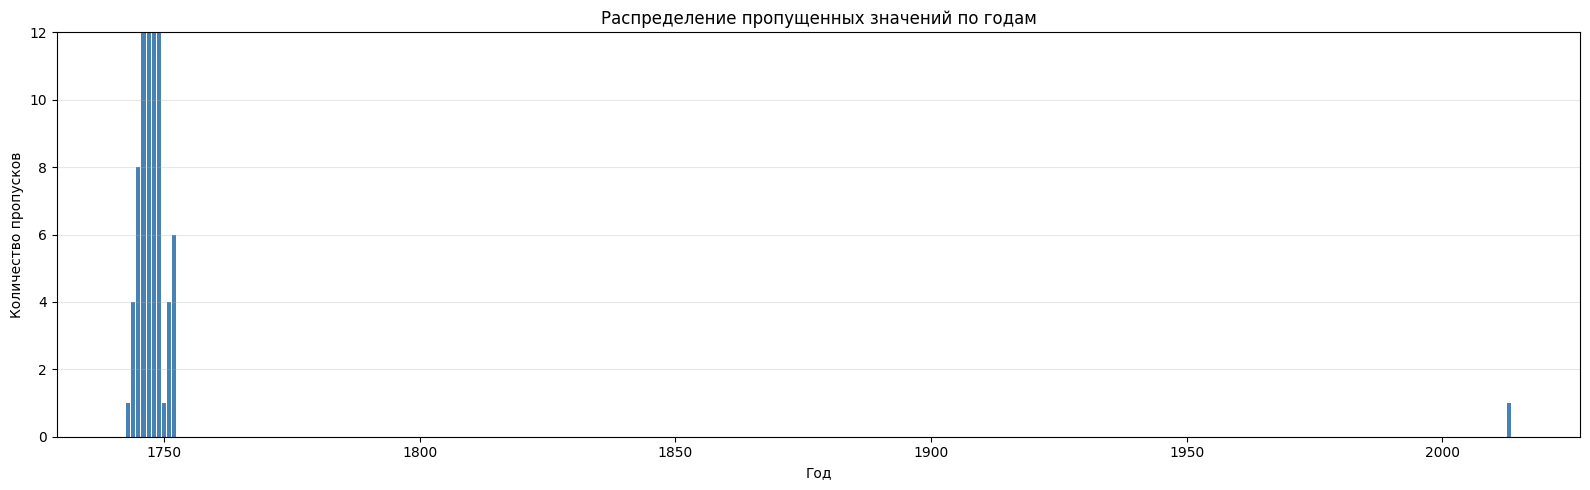

In [126]:
# Распределение пропущенных значений по годам
fig, ax = plt.subplots(figsize=(16, 5))

ax.bar(
    missing_by_year.index,
    missing_by_year["missing_count"],
    color="steelblue",
    width=0.8,
)

ax.set_title("Распределение пропущенных значений по годам")
ax.set_xlabel("Год")
ax.set_ylabel("Количество пропусков")
ax.set_ylim(0, 12)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### 1.4.3. Распределение пропущенных значений по календарным месяцам

Среднемесячная температура характеризуется выраженной годовой сезонностью.

Для определения возможной зависимости пропусков от календарного месяца рассчитаем количество
и долю пропущенных значений для каждого месяца года.

In [127]:
# Расчет статистики пропущенных значений по месяцам
missing_by_month = (
    temperature_series.isna()
    .groupby(temperature_series.index.month)
    .agg(["size", "sum", "mean"])
    .rename(
        columns={
            "size": "observations_count",
            "sum": "missing_count",
            "mean": "missing_percent",
        }
    )
)

missing_by_month.index.name = "month"
missing_by_month["missing_percent"] *= 100

missing_by_month.round(2)

,observations_count,missing_count,missing_percent
month,,,
1,270,5,1.85
2,270,6,2.22
3,270,5,1.85
4,270,4,1.48
5,270,7,2.59
6,270,6,2.22
7,270,6,2.22
8,270,7,2.59
9,270,7,2.59


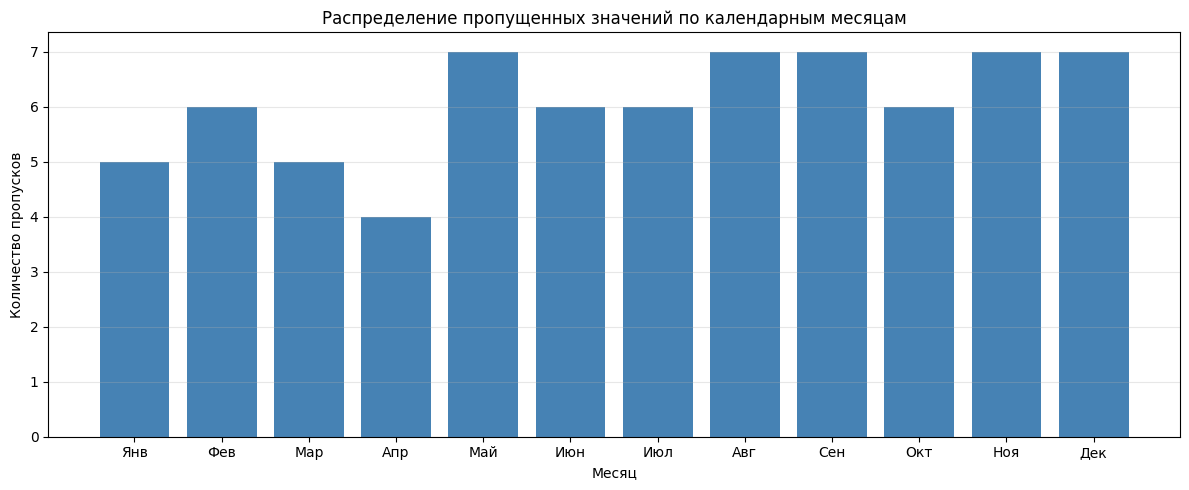

In [128]:
# Распределение пропущенных значений по календарным месяцам
month_labels = [
    "Янв", "Фев", "Мар", "Апр",
    "Май", "Июн", "Июл", "Авг",
    "Сен", "Окт", "Ноя", "Дек",
]

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    missing_by_month.index,
    missing_by_month["missing_count"],
    color="steelblue",
)

ax.set_title(
    "Распределение пропущенных значений по календарным месяцам"
)
ax.set_xlabel("Месяц")
ax.set_ylabel("Количество пропусков")
ax.set_xticks(range(1, 13), labels=month_labels)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### 1.4.4. Анализ непрерывных последовательностей пропущенных значений

Для выбора метода восстановления данных необходимо учитывать также продолжительность их непрерывных последовательностей.

Определим отдельные интервалы пропущенных наблюдений, их начальные и конечные даты, а также продолжительность в месяцах.

In [129]:
# Формирование индикатора пропущенных значений
missing_mask = temperature_series.isna()

# Новая группа формируется при изменении состояния наблюдения
group_ids = missing_mask.ne(missing_mask.shift()).cumsum()

# Формирование таблицы непрерывных последовательностей
observation_groups = (
    pd.DataFrame(
        {
            "date": temperature_series.index,
            "is_missing": missing_mask.to_numpy(),
            "group_id": group_ids.to_numpy(),
        }
    )
    .groupby("group_id")
    .agg(
        start_date=("date", "min"),
        end_date=("date", "max"),
        duration_months=("date", "size"),
        is_missing=("is_missing", "first"),
    )
)

# Выделение последовательностей пропущенных наблюдений
missing_periods = (
    observation_groups.loc[observation_groups["is_missing"]]
    .drop(columns="is_missing")
    .reset_index(drop=True)
)

missing_periods

,start_date,end_date,duration_months
0,1743-12-01,1744-03-01,4
1,1744-08-01,1744-08-01,1
2,1745-05-01,1749-12-01,56
3,1750-11-01,1750-11-01,1
4,1751-05-01,1751-05-01,1
5,1751-10-01,1751-12-01,3
6,1752-02-01,1752-02-01,1
7,1752-05-01,1752-09-01,5
8,2013-09-01,2013-09-01,1


In [130]:
# Проверка корректности выделения пропущенных интервалов
assert missing_periods["duration_months"].sum() == missing_count

print(
    f"Количество отдельных интервалов пропусков: "
    f"{len(missing_periods)}"
)
print(
    f"Максимальная продолжительность пропуска: "
    f"{missing_periods['duration_months'].max()} мес"
)
print(
    f"Количество одиночных пропусков: "
    f"{missing_periods['duration_months'].eq(1).sum()}"
)
print(
    f"Количество интервалов из двух и более пропусков: "
    f"{missing_periods['duration_months'].gt(1).sum()}"
)

Количество отдельных интервалов пропусков: 9
Максимальная продолжительность пропуска: 56 мес
Количество одиночных пропусков: 5
Количество интервалов из двух и более пропусков: 4


In [131]:
# Наиболее продолжительные интервалы пропущенных наблюдений
missing_periods.sort_values(
    "duration_months",
    ascending=False,
).head(10)

,start_date,end_date,duration_months
2,1745-05-01,1749-12-01,56
7,1752-05-01,1752-09-01,5
0,1743-12-01,1744-03-01,4
5,1751-10-01,1751-12-01,3
1,1744-08-01,1744-08-01,1
3,1750-11-01,1750-11-01,1
4,1751-05-01,1751-05-01,1
6,1752-02-01,1752-02-01,1
8,2013-09-01,2013-09-01,1


In [132]:
# Распределение интервалов по продолжительности
missing_periods["duration_months"].value_counts().sort_index()

duration_months
1     5
3     1
4     1
5     1
56    1
Name: count, dtype: int64

#### 1.4.5. Анализ непрерывных периодов без пропущенных значений

Учитывая значительную продолжительность исходного временного ряда,
исследуем наличие длительных интервалов с полными наблюдениями.

Использование непрерывного периода без пропущенных значений
может позволить сохранить фактическую сезонную динамику температур,
избежать искусственного восстановления наблюдений
и снизить риск утечки данных при их подготовке.

In [133]:
# Выделение непрерывных периодов без пропущенных значений
complete_periods = (
    observation_groups.loc[~observation_groups["is_missing"]]
    .drop(columns="is_missing")
    .reset_index(drop=True)
)

assert (
    complete_periods["duration_months"].sum()
    == temperature_series.count()
)

# Наиболее продолжительные периоды с полными наблюдениями
complete_periods.sort_values(
    "duration_months",
    ascending=False,
).head(10)

,start_date,end_date,duration_months
8,1752-10-01,2013-08-01,3131
3,1750-01-01,1750-10-01,10
2,1744-09-01,1745-04-01,8
4,1750-12-01,1751-04-01,5
1,1744-04-01,1744-07-01,4
5,1751-06-01,1751-09-01,4
7,1752-03-01,1752-04-01,2
0,1743-11-01,1743-11-01,1
6,1752-01-01,1752-01-01,1


In [134]:
# Характеристики наиболее продолжительного полного периода
longest_complete_period = complete_periods.loc[
    complete_periods["duration_months"].idxmax()
]

print(
    f"Начало периода: "
    f"{longest_complete_period['start_date']:%Y-%m-%d}"
)
print(
    f"Конец периода: "
    f"{longest_complete_period['end_date']:%Y-%m-%d}"
)
print(
    f"Продолжительность: "
    f"{longest_complete_period['duration_months']} мес."
)
print(
    f"Продолжительность в годах: "
    f"{longest_complete_period['duration_months'] / 12:.2f}"
)
print(
    f"Доля от исходного временного ряда: "
    f"{longest_complete_period['duration_months'] / len(temperature_series):.2%}"
)

Начало периода: 1752-10-01
Конец периода: 2013-08-01
Продолжительность: 3131 мес.
Продолжительность в годах: 260.92
Доля от исходного временного ряда: 96.67%


**Выводы**

- Во временном ряду выявлено `73` пропущенных значения (`2,25%`), образующих `9` отдельных непрерывных интервалов.
- Основная часть пропусков (`72` наблюдения) сосредоточена в раннем историческом периоде с 1743 по 1752 год.
- Максимальная продолжительность непрерывной последовательности пропусков составляет `56` месяцев (с мая 1745 года по декабрь 1749 года).
- Последнее наблюдение за сентябрь 2013 года также содержит пропущенное значение температуры.
- Количество пропусков по календарным месяцам варьируется от `4` до `7`. Выраженной концентрации пропусков в определенном сезоне не выявлено.
- Наиболее продолжительный непрерывный период без пропущенных значений охватывает интервал с октября 1752 года по август 2013 года
  и содержит `3 131` наблюдение (`96,67%` исходного временного ряда).

Учитывая значительную продолжительность периода с полными наблюдениями,
для дальнейшего исследования целесообразно использовать данный интервал
без искусственного восстановления пропущенных температур.

Такой подход позволяет сохранить регулярную месячную частоту и фактическую сезонную динамику температур,
а также исключить риск утечки данных при заполнении пропущенных значений.

### 1.5. Обработка пропущенных значений

По результатам анализа пропущенных значений принято решение ограничить исследуемый временной ряд
наиболее продолжительным непрерывным периодом с полными наблюдениями.

**Обоснование выбранного подхода:**

- основная часть пропусков сосредоточена в раннем историческом периоде
- максимальная продолжительность последовательности пропусков составляет `56` месяцев, что затрудняет корректное восстановление температур
- непрерывный период без пропусков содержит `96,67%` исходных календарных наблюдений
- объем сохраняемых данных достаточен для формирования обучающей и тестовой выборок, скользящих окон и лаговых признаков

Заполнение пропусков с помощью интерполяции, переноса предыдущих значений или сезонных средних не применяется,
так как это может привести к искажению исторической динамики.

Вместо удаления отдельных наблюдений ограничим начальную и конечную границы временного ряда,
сохранив его регулярную месячную структуру.

Границы исследуемого периода определены ретроспективно на основании полноты исходных наблюдений.
Такой подход допустим для данного учебного исследования, однако при построении системы прогнозирования в реальном времени
необходимо учитывать только информацию, доступную на момент формирования прогноза.

In [135]:
# Выделение непрерывного периода с полными наблюдениями
prepared_temperature_series = temperature_series.loc[
    longest_complete_period["start_date"]:
    longest_complete_period["end_date"]
].copy()

prepared_temperature_series.head(12)

dt
1752-10-01     5.644
1752-11-01     1.910
1752-12-01    -2.712
1753-01-01    -7.122
1753-02-01    -6.956
1753-03-01     0.706
1753-04-01     6.768
1753-05-01    13.060
1753-06-01    16.615
1753-07-01    18.032
1753-08-01    16.501
1753-09-01    12.448
Freq: MS, Name: AverageTemperature, dtype: float64

In [136]:
# Просмотр последних наблюдений подготовленного ряда
prepared_temperature_series.tail(12)

dt
2012-09-01    13.680
2012-10-01     7.188
2012-11-01     3.804
2012-12-01    -6.036
2013-01-01    -6.989
2013-02-01    -1.969
2013-03-01    -4.565
2013-04-01     6.900
2013-05-01    16.744
2013-06-01    19.070
2013-07-01    18.710
2013-08-01    18.231
Freq: MS, Name: AverageTemperature, dtype: float64

In [137]:
# Основные характеристики подготовленного временного ряда
print(f"Страна: {COUNTRY}")
print(f"Количество наблюдений: {len(prepared_temperature_series):,}")
print(
    f"Начало периода: "
    f"{prepared_temperature_series.index.min():%Y-%m-%d}"
)
print(
    f"Конец периода: "
    f"{prepared_temperature_series.index.max():%Y-%m-%d}"
)
print(f"Частота: {prepared_temperature_series.index.freqstr}")
print(
    f"Количество пропусков: "
    f"{prepared_temperature_series.isna().sum()}"
)

Страна: Belarus
Количество наблюдений: 3,131
Начало периода: 1752-10-01
Конец периода: 2013-08-01
Частота: MS
Количество пропусков: 0


In [138]:
# Проверка структуры и полноты подготовленного временного ряда
assert isinstance(
    prepared_temperature_series.index,
    pd.DatetimeIndex,
)
assert prepared_temperature_series.index.is_unique
assert prepared_temperature_series.index.is_monotonic_increasing
assert prepared_temperature_series.index.is_month_start.all()
assert prepared_temperature_series.index.freqstr == FREQUENCY
assert prepared_temperature_series.notna().all()
assert np.isfinite(prepared_temperature_series).all()

assert (
    len(prepared_temperature_series)
    == longest_complete_period["duration_months"]
)

In [139]:
# Проверка непрерывности календарного диапазона
prepared_expected_index = pd.date_range(
    start=prepared_temperature_series.index.min(),
    end=prepared_temperature_series.index.max(),
    freq=FREQUENCY,
)

assert prepared_temperature_series.index.equals(
    prepared_expected_index
)

print("Проверка регулярности временного ряда пройдена")

Проверка регулярности временного ряда пройдена


#### 1.5.1. Сравнение исходного и подготовленного временных рядов

Для оценки влияния выбранного способа обработки пропущенных значений сравним
основные характеристики временного ряда до и после ограничения исследуемого периода.

Дополнительно определим количество исключенных календарных наблюдений и известных значений температуры.

In [140]:
# Сравнение характеристик исходного и подготовленного рядов
series_comparison = pd.DataFrame(
    {
        "original": {
            "start_date": temperature_series.index.min(),
            "end_date": temperature_series.index.max(),
            "observations_count": len(temperature_series),
            "valid_count": temperature_series.count(),
            "missing_count": temperature_series.isna().sum(),
            "frequency": temperature_series.index.freqstr,
        },
        "prepared": {
            "start_date": prepared_temperature_series.index.min(),
            "end_date": prepared_temperature_series.index.max(),
            "observations_count": len(prepared_temperature_series),
            "valid_count": prepared_temperature_series.count(),
            "missing_count": prepared_temperature_series.isna().sum(),
            "frequency": prepared_temperature_series.index.freqstr,
        },
    }
)

series_comparison

,original,prepared
start_date,1743-11-01 00:00:00,1752-10-01 00:00:00
end_date,2013-09-01 00:00:00,2013-08-01 00:00:00
observations_count,3239,3131
valid_count,3166,3131
missing_count,73,0
frequency,MS,MS


In [141]:
# Оценка объема исключенных данных
excluded_observations_count = (
    len(temperature_series) - len(prepared_temperature_series)
)

excluded_valid_count = (
    temperature_series.count() - prepared_temperature_series.count()
)

retained_observations_ratio = (
    len(prepared_temperature_series) / len(temperature_series)
)

retained_valid_ratio = (
    prepared_temperature_series.count() / temperature_series.count()
)

print(f"Исключено наблюдений: {excluded_observations_count}")
print(f"Исключено известных температур: {excluded_valid_count}")
print(f"Сохранено календарных наблюдений: {retained_observations_ratio:.2%}")
print(f"Сохранено известных температур: {retained_valid_ratio:.2%}")

Исключено наблюдений: 108
Исключено известных температур: 35
Сохранено календарных наблюдений: 96.67%
Сохранено известных температур: 98.89%


### 1.6. Визуализация и анализ временного ряда

После подготовки данных исследуем динамику среднемесячных температур,
их распределение и основные особенности временного ряда.

Особое внимание уделяется наличию сезонных колебаний,
так как сезонная структура температур должна учитываться
при последующей генерации признаков и построении прогнозной модели.

**Примечание:**

Описательный анализ выполняется на всем подготовленном историческом ряде для изучения его общих характеристик.
Полученные агрегированные статистики не используются при обучении модели, преобразовании признаков или подборе ее параметров.
После хронологического разбиения все операции, связанные с обучением модели, будут выполняться исключительно на обучающей выборке.

#### 1.6.1. Сравнение исходного и подготовленного временных рядов

Визуализируем исходный и подготовленный временные ряды, обозначив границы выбранного исследуемого периода.

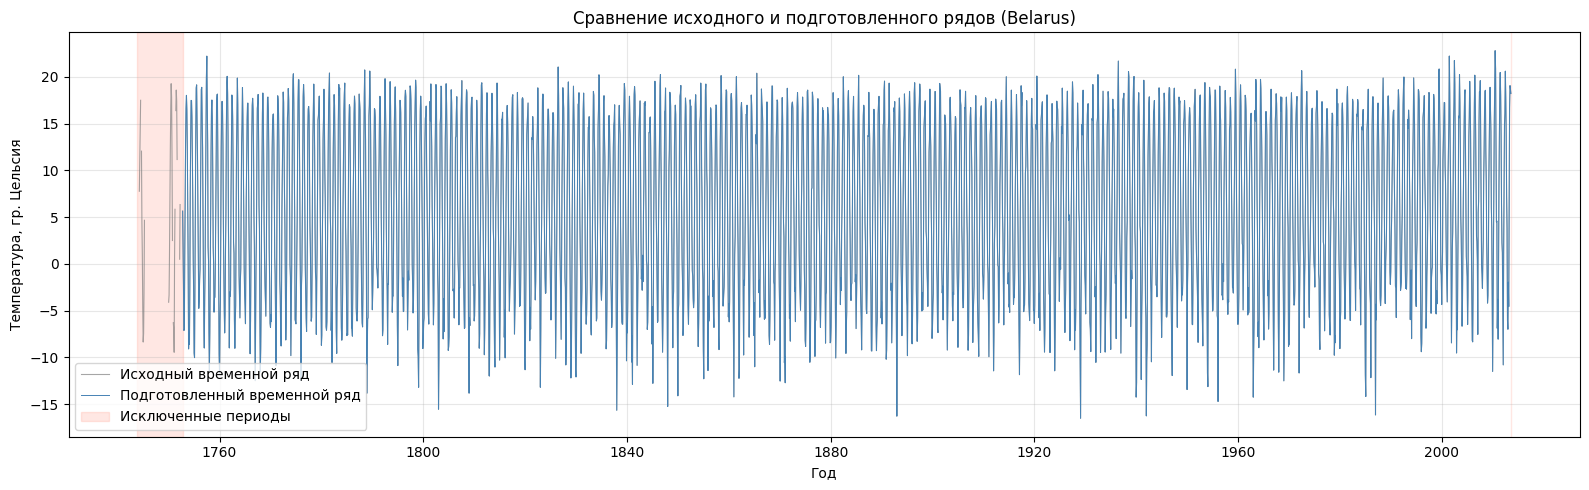

In [142]:
# Сравнение исходного и подготовленного временных рядов
fig, ax = plt.subplots(figsize=(16, 5))

ax.plot(
    temperature_series.index,
    temperature_series,
    color="gray",
    linewidth=0.8,
    alpha=0.7,
    label="Исходный временной ряд",
)

ax.plot(
    prepared_temperature_series.index,
    prepared_temperature_series,
    color="steelblue",
    linewidth=0.7,
    label="Подготовленный временной ряд",
)

ax.axvspan(
    temperature_series.index.min(),
    prepared_temperature_series.index.min(),
    color="tomato",
    alpha=0.15,
    label="Исключенные периоды",
)

ax.axvspan(
    prepared_temperature_series.index.max(),
    temperature_series.index.max(),
    color="tomato",
    alpha=0.15,
)

ax.set_title(f"Сравнение исходного и подготовленного рядов ({COUNTRY})")
ax.set_xlabel("Год")
ax.set_ylabel("Температура, гр. Цельсия")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### 1.6.2. Динамика среднемесячных температур

Построим график подготовленного временного ряда за весь исследуемый период.

Дополнительно рассчитаем скользящее среднее с окном `12` месяцев
для визуального сглаживания сезонных колебаний и предварительной оценки долгосрочной динамики температур.

Скользящее среднее используется исключительно для исследовательского анализа
и не включается в набор признаков прогнозной модели.

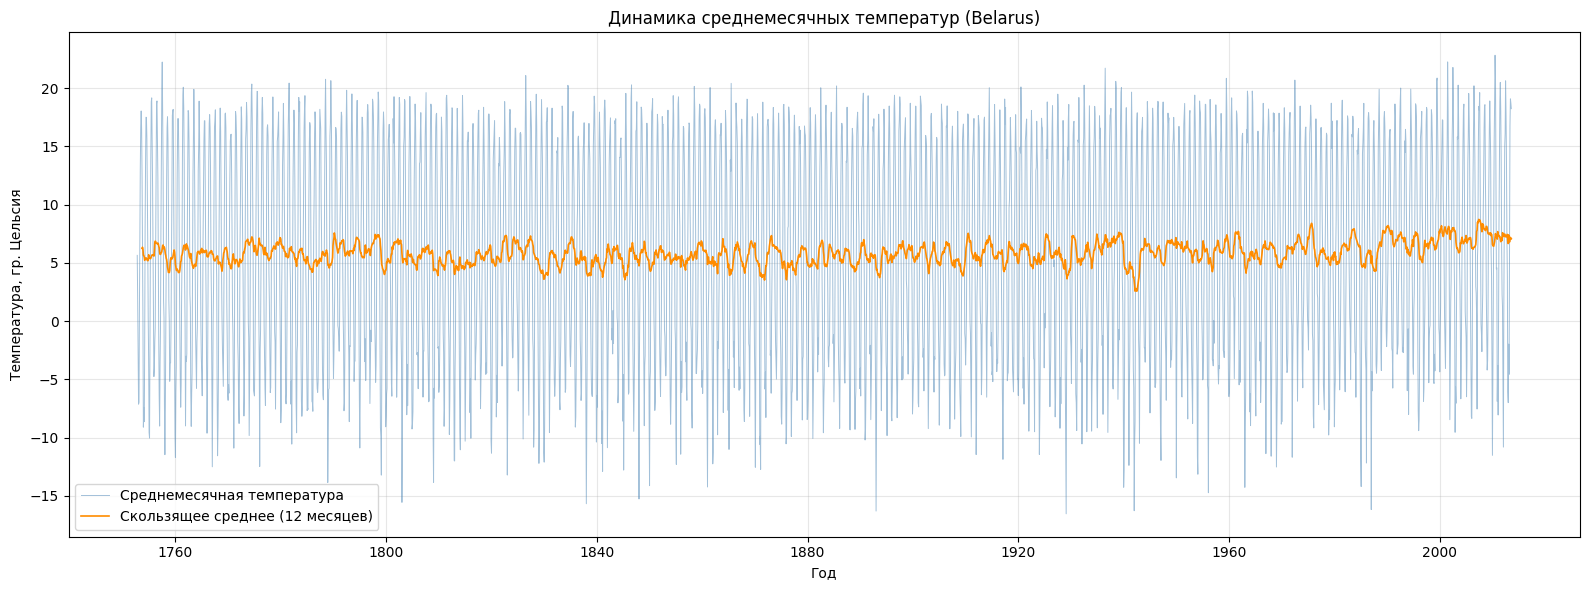

In [143]:
# Расчет скользящего среднего за предыдущие 12 месяцев
rolling_mean = prepared_temperature_series.rolling(
    window=12,
    min_periods=12,
).mean()

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(
    prepared_temperature_series.index,
    prepared_temperature_series,
    color="steelblue",
    linewidth=0.7,
    alpha=0.5,
    label="Среднемесячная температура",
)

ax.plot(
    rolling_mean.index,
    rolling_mean,
    color="darkorange",
    linewidth=1.2,
    label="Скользящее среднее (12 месяцев)",
)

ax.set_title(f"Динамика среднемесячных температур ({COUNTRY})")
ax.set_xlabel("Год")
ax.set_ylabel("Температура, гр. Цельсия")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### 1.6.3. Анализ сезонных колебаний

На графике всего временного ряда отдельные годовые циклы сложно различить из-за значительной продолжительности исследуемого периода.

Для более детального изучения сезонной структуры визуализируем первые `120` месяцев подготовленного ряда, соответствующие десяти годам наблюдений.

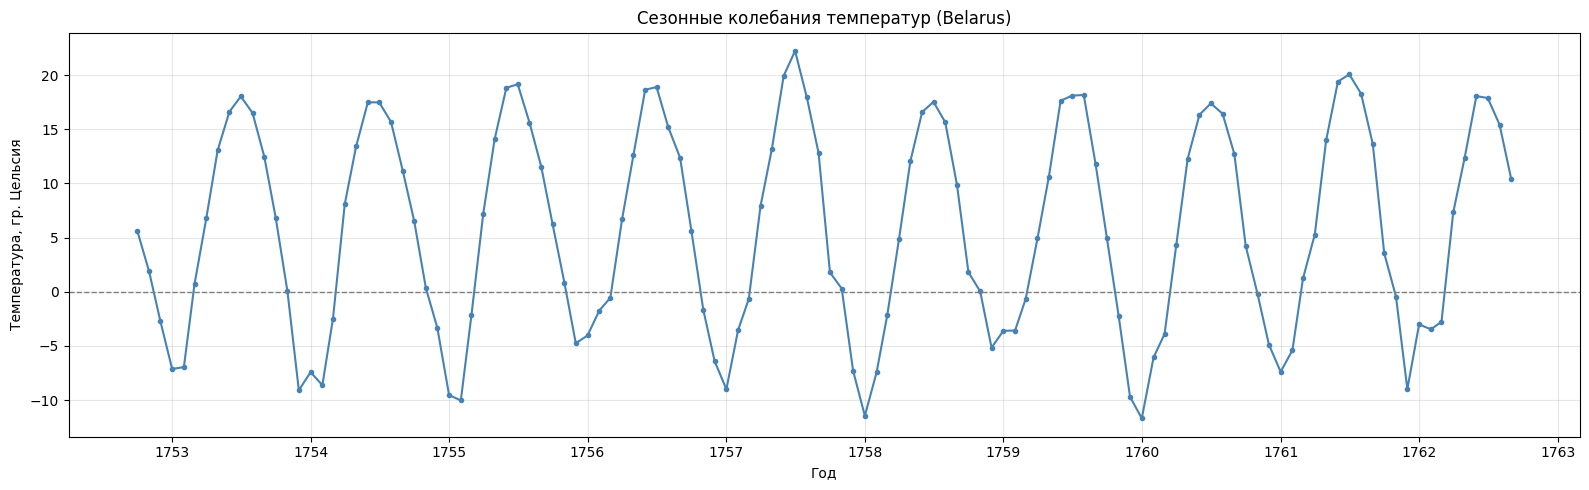

In [144]:
# Выделение первых десяти лет наблюдений
seasonal_period = prepared_temperature_series.iloc[:120]

fig, ax = plt.subplots(figsize=(16, 5))

ax.plot(
    seasonal_period.index,
    seasonal_period,
    color="steelblue",
    linewidth=1.5,
    marker="o",
    markersize=3,
)

ax.axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1,
)

ax.set_title(f"Сезонные колебания температур ({COUNTRY})")
ax.set_xlabel("Год")
ax.set_ylabel("Температура, гр. Цельсия")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### 1.6.4. Описательная статистика температур

Рассчитаем основные статистические характеристики подготовленного временного ряда:

- среднее значение
- стандартное отклонение
- минимальную и максимальную температуры
- медиану и квартили распределения

Дополнительно определим количество отрицательных, нулевых и близких к нулю значений температуры.

Последняя проверка необходима для дальнейшей корректной интерпретации метрики MAPE, чувствительной к малым абсолютным значениям целевой переменной.

Близкими к нулю считаются температуры, абсолютное значение которых меньше `1 гр. Цельсия`.
Данный порог используется исключительно для диагностического анализа.

Категория `near_zero` пересекается с категориями отрицательных, нулевых и положительных температур,
поэтому сумма долей всех представленных категорий может превышать `100%`.

In [145]:
# Описательная статистика подготовленного временного ряда
prepared_temperature_series.describe().round(3)

count    3131.000
mean        5.828
std         9.179
min       -16.527
25%        -2.232
50%         5.926
75%        14.710
max        22.811
Name: AverageTemperature, dtype: float64

In [146]:
# Анализ отрицательных и близких к нулю температур
temperature_statistics = pd.DataFrame(
    {
        "count": {
            "negative": prepared_temperature_series.lt(0).sum(),
            "zero": prepared_temperature_series.eq(0).sum(),
            "near_zero": (
                prepared_temperature_series.abs().lt(1).sum()
            ),
            "positive": prepared_temperature_series.gt(0).sum(),
        }
    }
)

temperature_statistics["percent"] = (
    temperature_statistics["count"]
    / len(prepared_temperature_series)
    * 100
)

temperature_statistics.round(3)

,count,percent
negative,1055,33.695
zero,0,0.000
near_zero,216,6.899
positive,2076,66.305


#### 1.6.5. Распределение температур по календарным месяцам

Для количественной оценки годовой сезонности рассчитаем статистические характеристики температур в разрезе календарных месяцев.

Сравнение среднемесячных температур и их вариативности позволит оценить выраженность сезонного цикла
и обосновать использование календарных признаков и годового лага (`t-12`).

На графике дополнительно отображается диапазон в пределах одного стандартного отклонения
относительно средней температуры каждого календарного месяца.
Данный диапазон характеризует изменчивость исторических температур и не является доверительным интервалом.

Статистики рассчитываются в исследовательских целях и не используются непосредственно в качестве признаков модели.

In [147]:
# Расчет статистики температур по календарным месяцам
monthly_temperature_stats = (
    prepared_temperature_series
    .groupby(prepared_temperature_series.index.month)
    .agg(["count", "mean", "std", "min", "median", "max"])
)

monthly_temperature_stats.index.name = "month"

monthly_temperature_stats.round(3)

,count,mean,std,min,median,max
month,,,,,,
1,261,-6.784,3.453,-16.290,-6.415,0.448
2,261,-5.799,3.171,-16.527,-5.758,2.678
3,261,-1.442,2.554,-8.668,-1.198,5.490
4,261,5.961,1.896,0.287,5.868,11.054
5,261,12.675,1.791,7.566,12.576,17.383
6,261,16.425,1.457,12.628,16.401,20.587
7,261,18.127,1.394,14.414,18.100,22.811
8,261,16.921,1.324,13.679,16.809,20.877
9,260,11.997,1.352,8.393,11.977,15.210


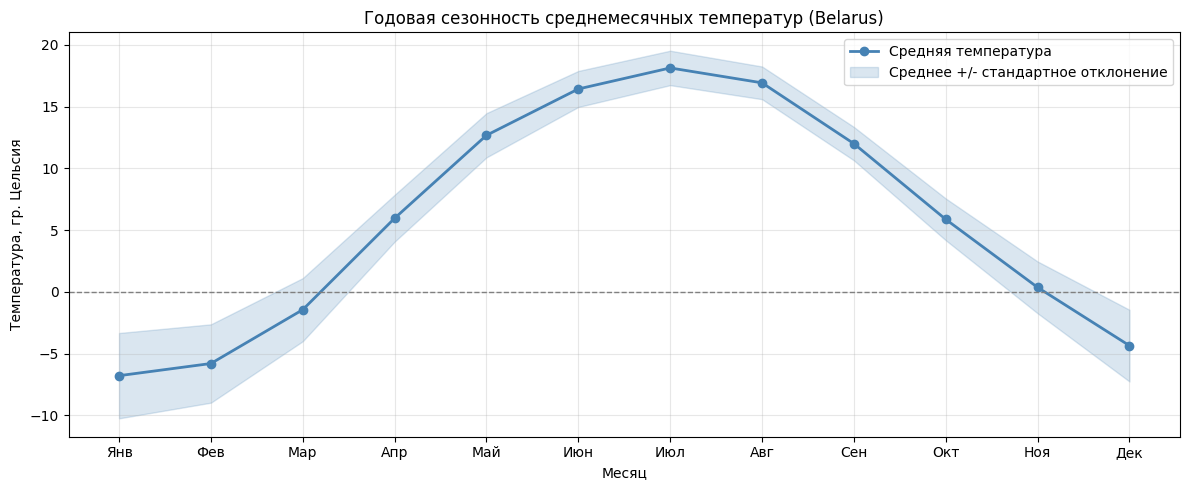

In [148]:
# Визуализация средних температур по календарным месяцам
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly_temperature_stats.index,
    monthly_temperature_stats["mean"],
    color="steelblue",
    marker="o",
    linewidth=2,
    label="Средняя температура",
)

ax.fill_between(
    monthly_temperature_stats.index,
    monthly_temperature_stats["mean"] - monthly_temperature_stats["std"],
    monthly_temperature_stats["mean"] + monthly_temperature_stats["std"],
    color="steelblue",
    alpha=0.2,
    label="Среднее +/- стандартное отклонение",
)

ax.axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1,
)

ax.set_title(f"Годовая сезонность среднемесячных температур ({COUNTRY})")
ax.set_xlabel("Месяц")
ax.set_ylabel("Температура, гр. Цельсия")
ax.set_xticks(range(1, 13), labels=month_labels)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 1.7. Выводы по этапу подготовки данных

В ходе первого этапа выполнена подготовка и исследовательский анализ временного ряда среднемесячных температур для выбранной страны (`Belarus`).

**Подготовка данных:**

- исходный временной ряд содержит `3 239` наблюдений за период с ноября 1743 года по сентябрь 2013 года
- даты наблюдений преобразованы в `DatetimeIndex`, отсортированы в хронологическом порядке и приведены к регулярной месячной частоте (`MS`)
- выявлено `73` пропущенных значения (`2,25%`), преимущественно сосредоточенных в раннем историческом периоде
- максимальная продолжительность непрерывной последовательности пропусков составляет `56` месяцев
- для дальнейшего исследования выбран наиболее продолжительный непрерывный период без пропущенных значений (с октября 1752 года по август 2013 года)
- подготовленный временной ряд содержит `3 131` наблюдение, что составляет `96,67%` исходных календарных наблюдений
  и `98,89%` известных температур
- искусственное восстановление пропущенных значений не применялось

**Основные характеристики временного ряда:**

- средняя температура составляет `5,828 гр. Цельсия`, медиана `5,926 гр. Цельсия`
- минимальная наблюдаемая температура составляет `-16,527 гр. Цельсия`, максимальная `22,811 гр. Цельсия`
- выявлена выраженная годовая сезонность с периодом `12` месяцев
- минимальная среднемесячная температура наблюдается в январе (`-6,784 гр. Цельсия`), максимальная в июле (`18,127 гр. Цельсия`)
- размах средних температур по календарным месяцам составляет `24,911 гр. Цельсия`
- изменчивость температур в зимние месяцы выше, чем в летние

**Особенности последующего моделирования:**

- регулярная месячная частота позволяет корректно формировать лаговые признаки `t-1` и `t-12`
- выраженная годовая сезонность обосновывает использование годового лага и календарных признаков
- нулевые значения температуры отсутствуют, однако `216` наблюдений (`6,90%`) имеют абсолютное значение менее `1 гр. Цельсия`,
  что необходимо учитывать при интерпретации метрики MAPE
- при разделении данных, генерации признаков и обучении модели необходимо сохранять хронологический порядок наблюдений
  и исключать использование будущих значений температуры

В результате сформирован непрерывный одномерный временной ряд без пропущенных и бесконечных значений,
пригодный для хронологического разбиения, генерации признаков и последующего прогнозирования.

## 2. Хронологическое разделение на обучающую и тестовую выборки (Holdout)

**Цель этапа**

Разделить подготовленный временной ряд на обучающую и тестовую выборки
с сохранением хронологического порядка наблюдений и сформировать основу для последующей оценки качества прогнозной модели.

На данном этапе необходимо:

- разделить временной ряд в пропорции `80/20`
- сохранить хронологический порядок наблюдений
- проверить отсутствие пересечений между выборками
- проверить непрерывность календарного диапазона
- визуализировать обучающую и тестовую выборки

### 2.1. Формирование обучающей и тестовой выборок

Для оценки качества прогнозирования используется метод отложенной выборки (Holdout).

В отличие от случайного разбиения, применяемого в классических задачах машинного обучения,
для временных рядов необходимо сохранять последовательность наблюдений.

Первые `80%` наблюдений используются для обучения модели (`train`), последние `20%` для оценки качества прогнозирования (`test`).

Перемешивание наблюдений не выполняется, так как это нарушило бы временную структуру данных
и могло бы привести к использованию будущих наблюдений при обучении модели.

In [149]:
# Хронологическое разделение временного ряда
train_series, test_series = split_temperature_series(
    prepared_temperature_series,
    test_size=TEST_SIZE,
)

print(f"Всего наблюдений: {len(prepared_temperature_series):,}")
print(f"Обучающая выборка: {len(train_series):,}")
print(f"Тестовая выборка: {len(test_series):,}")

print(
    f"Доля обучающей выборки: "
    f"{len(train_series) / len(prepared_temperature_series):.2%}"
)
print(
    f"Доля тестовой выборки: "
    f"{len(test_series) / len(prepared_temperature_series):.2%}"
)

Всего наблюдений: 3,131
Обучающая выборка: 2,504
Тестовая выборка: 627
Доля обучающей выборки: 79.97%
Доля тестовой выборки: 20.03%


In [150]:
# Основные характеристики обучающей и тестовой выборок
split_statistics = pd.DataFrame(
    {
        "train": {
            "start_date": train_series.index.min(),
            "end_date": train_series.index.max(),
            "observations_count": len(train_series),
            "missing_count": train_series.isna().sum(),
            "frequency": train_series.index.freqstr,
        },
        "test": {
            "start_date": test_series.index.min(),
            "end_date": test_series.index.max(),
            "observations_count": len(test_series),
            "missing_count": test_series.isna().sum(),
            "frequency": test_series.index.freqstr,
        },
    }
)

split_statistics

,train,test
start_date,1752-10-01 00:00:00,1961-06-01 00:00:00
end_date,1961-05-01 00:00:00,2013-08-01 00:00:00
observations_count,2504,627
missing_count,0,0
frequency,MS,MS


### 2.2. Проверка корректности разбиения

Для подтверждения корректности хронологического разбиения проверим следующие условия:

- обучающая и тестовая выборки не являются пустыми
- суммарное количество наблюдений соответствует подготовленному временному ряду
- даты обучающей и тестовой выборок не пересекаются
- все обучающие наблюдения предшествуют тестовым
- между окончанием обучающей и началом тестовой выборок отсутствуют пропущенные календарные месяцы
- регулярная месячная частота сохраняется в обеих выборках
- объединение выборок полностью восстанавливает подготовленный временной ряд

Выполнение данных условий необходимо для сохранения временной структуры наблюдений и корректной последующей оценки прогнозной модели.

In [151]:
# Проверка размеров выборок
assert not train_series.empty
assert not test_series.empty

assert (
    len(train_series) + len(test_series)
    == len(prepared_temperature_series)
)

# Проверка отсутствия пересечения выборок
assert train_series.index.intersection(test_series.index).empty

# Проверка хронологического порядка
assert train_series.index.max() < test_series.index.min()

# Проверка непрерывности на границе выборок
assert (
    train_series.index.max() + pd.offsets.MonthBegin(1)
    == test_series.index.min()
)

# Проверка регулярности временных рядов
assert train_series.index.freqstr == FREQUENCY
assert test_series.index.freqstr == FREQUENCY

# Проверка отсутствия пропущенных значений
assert train_series.notna().all()
assert test_series.notna().all()

# Проверка сохранения исходных наблюдений
assert pd.concat([train_series, test_series]).equals(
    prepared_temperature_series
)

print("Все проверки корректности Holdout-разбиения пройдены")

Все проверки корректности Holdout-разбиения пройдены


### 2.3. Визуализация обучающей и тестовой выборок

Для наглядного представления хронологического разбиения построим общий график
подготовленного временного ряда с выделением обучающего и тестового периодов.

Граница разбиения обозначается вертикальной линией, соответствующей первому наблюдению тестовой выборки.

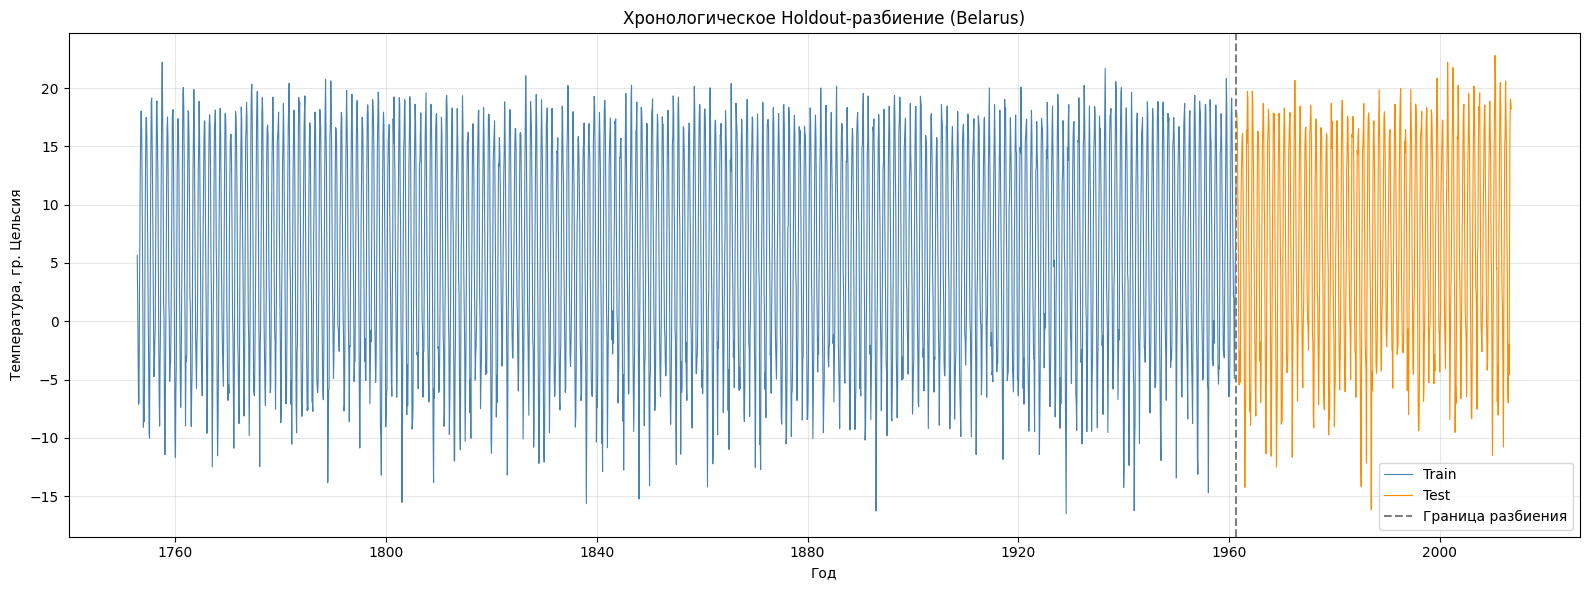

In [152]:
# Визуализация хронологического Holdout-разбиения
fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(
    train_series.index,
    train_series,
    color="steelblue",
    linewidth=0.8,
    label="Train",
)

ax.plot(
    test_series.index,
    test_series,
    color="darkorange",
    linewidth=0.8,
    label="Test",
)

ax.axvline(
    x=test_series.index.min(),
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="Граница разбиения",
)

ax.set_title(f"Хронологическое Holdout-разбиение ({COUNTRY})")
ax.set_xlabel("Год")
ax.set_ylabel("Температура, гр. Цельсия")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### 2.3.1. Детализация границы разбиения

Для дополнительной проверки непрерывности временного ряда визуализируем последние `24` месяца обучающей выборки
и первые `24` месяца тестовой выборки.

Данный график позволяет наглядно оценить сохранение последовательности наблюдений
и сезонных колебаний на границе train и test.

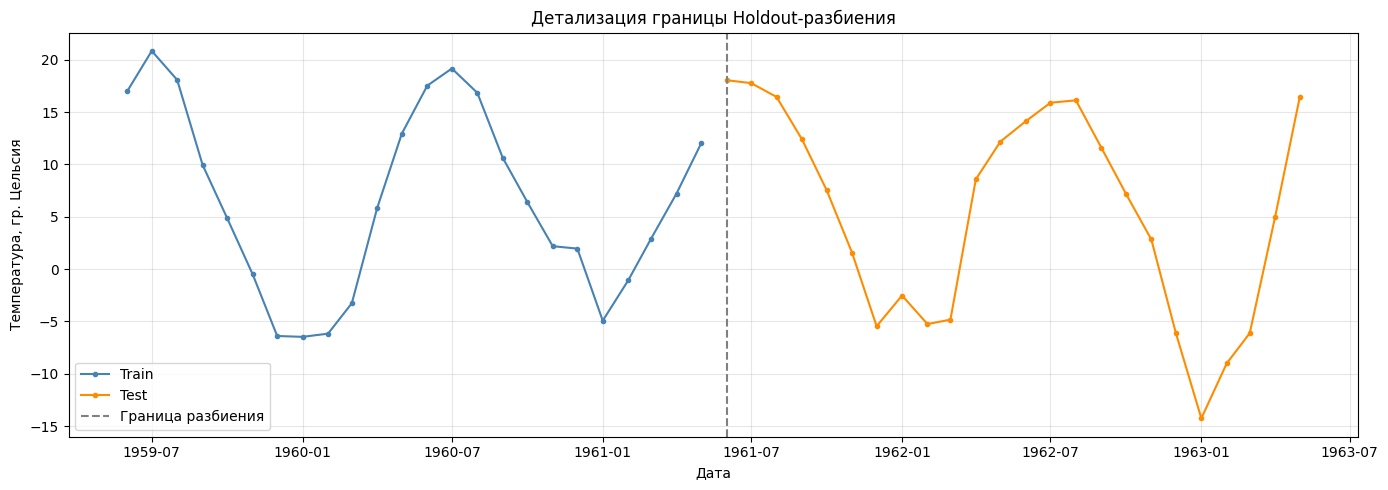

In [153]:
# Детализация временного ряда вблизи границы разбиения
train_boundary = train_series.tail(24)
test_boundary = test_series.head(24)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    train_boundary.index,
    train_boundary,
    color="steelblue",
    marker="o",
    markersize=3,
    label="Train",
)

ax.plot(
    test_boundary.index,
    test_boundary,
    color="darkorange",
    marker="o",
    markersize=3,
    label="Test",
)

ax.axvline(
    x=test_series.index.min(),
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="Граница разбиения",
)

ax.set_title("Детализация границы Holdout-разбиения")
ax.set_xlabel("Дата")
ax.set_ylabel("Температура, гр. Цельсия")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 2.4. Выводы по этапу Holdout-разбиения

В ходе второго этапа выполнено хронологическое разделение подготовленного временного ряда на обучающую и тестовую выборки.

**Результаты разбиения:**

- обучающая выборка (`train`) содержит `2 504` наблюдения (`79,97%`) за период с октября 1752 года по май 1961 года
- тестовая выборка (`test`) содержит `627` наблюдений (`20,03%`) за период с июня 1961 года по август 2013 года
- граница разбиения соответствует `1961-06-01`
- небольшое отклонение от заданной пропорции `80/20` обусловлено необходимостью разделения целого количества наблюдений

**Проверка корректности разбиения:**

- перемешивание наблюдений не выполнялось
- обучающая и тестовая выборки не пересекаются
- все обучающие наблюдения предшествуют тестовым
- между выборками отсутствуют пропущенные календарные месяцы
- регулярная месячная частота (`MS`) сохранена
- объединение выборок полностью восстанавливает подготовленный временной ряд

Построены графики общего Holdout-разбиения и детализации его границы.

Обучающая выборка будет использоваться для обучения модели и формирования скользящих окон,
а тестовая выборка для итоговой оценки качества прогнозирования.

Сформированное разбиение обеспечивает сохранение временной структуры наблюдений
и исключает использование тестовых целевых значений при обучении модели.

## 3. Разбиение методом скользящего окна (Rolling Window)

**Цель этапа**

Реализовать последовательное разбиение временного ряда методом скользящего окна
с фиксированным размером обучающей выборки и горизонтом прогнозирования.

На данном этапе необходимо:

- реализовать механизм формирования скользящих окон
- определить количество доступных разбиений
- проверить корректность размеров и временных границ каждого окна
- визуализировать первые два разбиения

### 3.1. Формирование скользящих окон

Метод Rolling Window позволяет формировать последовательные обучающие
и валидационные выборки, сохраняя хронологический порядок наблюдений.

Для каждого разбиения используются следующие параметры:

- размер обучающего окна (`TRAIN_WINDOW_SIZE`) -> `120` месяцев
- горизонт прогнозирования (`FORECAST_HORIZON`) -> `12` месяцев
- шаг смещения окна (`WINDOW_STEP`) -> `12` месяцев

Размер обучающего окна остается постоянным.
При переходе к следующему разбиению его начальная и конечная границы смещаются на заданное количество месяцев.

Шаг смещения выбран равным горизонту прогнозирования,
чтобы валидационные интервалы соседних разбиений не пересекались.

Скользящие окна формируются исключительно на обучающей выборке, полученной на предыдущем этапе.
Финальная тестовая выборка сохраняется для итоговой оценки качества прогнозирования.

In [154]:
# Формирование последовательных разбиений
rolling_splits = list(
    generate_rolling_splits(
        train_series,
        train_window_size=TRAIN_WINDOW_SIZE,
        forecast_horizon=FORECAST_HORIZON,
        step=WINDOW_STEP,
    )
)

print(f"Количество обучающих наблюдений: {len(train_series):,}")
print(f"Размер обучающего окна: {TRAIN_WINDOW_SIZE} мес.")
print(f"Горизонт прогнозирования: {FORECAST_HORIZON} мес.")
print(f"Шаг смещения окна: {WINDOW_STEP} мес.")
print(f"Количество разбиений: {len(rolling_splits)}")

Количество обучающих наблюдений: 2,504
Размер обучающего окна: 120 мес.
Горизонт прогнозирования: 12 мес.
Шаг смещения окна: 12 мес.
Количество разбиений: 198


#### 3.1.1. Определение количества разбиений

Количество полных скользящих окон зависит от длины исходного временного ряда,
размера обучающего окна, горизонта прогнозирования и шага смещения.

Ожидаемое количество разбиений определяется по формуле:

$$
N_{splits} = \left\lfloor \frac{N-W-H}{S} \right\rfloor + 1
$$

где:

- $N$ -> количество наблюдений
- $W$ -> размер обучающего окна
- $H$ -> горизонт прогнозирования
- $S$ -> шаг смещения окна

Неполные окна в конце временного ряда не формируются.

Сравним аналитически рассчитанное количество разбиений с фактическим результатом работы генератора.

In [155]:
# Расчет ожидаемого количества полных разбиений
expected_splits_count = (
    (
        len(train_series)
        - TRAIN_WINDOW_SIZE
        - FORECAST_HORIZON
    )
    // WINDOW_STEP
    + 1
)

assert len(rolling_splits) == expected_splits_count

print(f"Ожидаемое количество разбиений: {expected_splits_count}")
print(f"Фактическое количество разбиений: {len(rolling_splits)}")

Ожидаемое количество разбиений: 198
Фактическое количество разбиений: 198


#### 3.1.2. Анализ границ сформированных разбиений

Для каждого разбиения определим начальные и конечные даты обучающего и валидационного окон,
а также количество входящих в них наблюдений.

Сформированная таблица позволит проверить сохранение фиксированных размеров окон
и последовательное смещение их временных границ.

In [156]:
# Формирование таблицы характеристик скользящих окон
rolling_split_statistics = pd.DataFrame(
    [
        {
            "split": split_number,
            "train_start": train_window.index.min(),
            "train_end": train_window.index.max(),
            "train_size": len(train_window),
            "validation_start": validation_window.index.min(),
            "validation_end": validation_window.index.max(),
            "validation_size": len(validation_window),
        }
        for split_number, (
        train_window,
        validation_window,
    ) in enumerate(rolling_splits, start=1)
    ]
).set_index("split")

rolling_split_statistics.head()

,train_start,train_end,train_size,validation_start,validation_end,validation_size
split,,,,,,
1,1752-10-01,1762-09-01,120,1762-10-01,1763-09-01,12
2,1753-10-01,1763-09-01,120,1763-10-01,1764-09-01,12
3,1754-10-01,1764-09-01,120,1764-10-01,1765-09-01,12
4,1755-10-01,1765-09-01,120,1765-10-01,1766-09-01,12
5,1756-10-01,1766-09-01,120,1766-10-01,1767-09-01,12


In [157]:
# Просмотр последних сформированных разбиений
rolling_split_statistics.tail()

,train_start,train_end,train_size,validation_start,validation_end,validation_size
split,,,,,,
194,1945-10-01,1955-09-01,120,1955-10-01,1956-09-01,12
195,1946-10-01,1956-09-01,120,1956-10-01,1957-09-01,12
196,1947-10-01,1957-09-01,120,1957-10-01,1958-09-01,12
197,1948-10-01,1958-09-01,120,1958-10-01,1959-09-01,12
198,1949-10-01,1959-09-01,120,1959-10-01,1960-09-01,12


In [158]:
# Определение неиспользованного остатка обучающей выборки
last_validation_end = rolling_splits[-1][1].index.max()

unused_tail = train_series.loc[
    train_series.index > last_validation_end
    ]

print(
    f"Конец последнего валидационного окна: "
    f"{last_validation_end:%Y-%m-%d}"
)
print(f"Конец обучающей выборки: {train_series.index.max():%Y-%m-%d}")
print(f"Количество оставшихся наблюдений: {len(unused_tail)}")

Конец последнего валидационного окна: 1960-09-01
Конец обучающей выборки: 1961-05-01
Количество оставшихся наблюдений: 8


### 3.2. Проверка корректности скользящих окон

Для подтверждения корректности реализации Rolling Window проверим следующие условия для всех сформированных разбиений:

- размер обучающего окна соответствует `120` месяцам
- размер валидационного окна соответствует `12` месяцам
- обучающие и валидационные наблюдения не пересекаются внутри одного разбиения
- обучающие наблюдения предшествуют валидационным
- между обучающим и валидационным окнами отсутствуют пропущенные календарные месяцы
- регулярная месячная частота сохраняется
- пропущенные значения отсутствуют
- все наблюдения принадлежат обучающей выборке
- финальная тестовая выборка не используется при формировании окон

Дополнительно проверим фиксированный шаг смещения и отсутствие пересечений валидационных окон соседних разбиений.

In [159]:
# Проверка корректности каждого сформированного разбиения
for train_window, validation_window in rolling_splits:
    assert len(train_window) == TRAIN_WINDOW_SIZE
    assert len(validation_window) == FORECAST_HORIZON

    assert train_window.index.intersection(
        validation_window.index
    ).empty

    assert train_window.index.max() < validation_window.index.min()

    assert (
        train_window.index.max() + pd.offsets.MonthBegin(1)
        == validation_window.index.min()
    )

    assert train_window.index.freqstr == FREQUENCY
    assert validation_window.index.freqstr == FREQUENCY

    assert train_window.notna().all()
    assert validation_window.notna().all()

    assert train_window.index.isin(train_series.index).all()
    assert validation_window.index.isin(train_series.index).all()

    assert train_window.index.intersection(test_series.index).empty
    assert validation_window.index.intersection(test_series.index).empty

print(f"Проверено разбиений: {len(rolling_splits)}")
print("Все проверки корректности скользящих окон пройдены")

Проверено разбиений: 198
Все проверки корректности скользящих окон пройдены


In [160]:
# Проверка смещения границ соседних скользящих окон
for previous_split, current_split in zip(
    rolling_splits[:-1],
    rolling_splits[1:],
    strict=True,
):
    previous_train, previous_validation = previous_split
    current_train, current_validation = current_split

    assert (
        previous_train.index.min() + pd.DateOffset(months=WINDOW_STEP)
        == current_train.index.min()
    )

    assert (
        previous_train.index.max() + pd.DateOffset(months=WINDOW_STEP)
        == current_train.index.max()
    )

    assert (
        previous_validation.index.min()
        + pd.DateOffset(months=WINDOW_STEP)
        == current_validation.index.min()
    )

    assert previous_validation.index.intersection(
        current_validation.index
    ).empty

print("Проверка смещения соседних окон пройдена")

Проверка смещения соседних окон пройдена


### 3.3. Визуализация скользящих окон

Для наглядного представления метода Rolling Window визуализируем первые два сформированных разбиения.

На графиках будут отображены:

- обучающее окно продолжительностью `120` месяцев
- валидационное окно продолжительностью `12` месяцев
- граница между обучающим и валидационным окнами
- смещение временных границ на `12` месяцев при переходе к следующему разбиению

Для удобства сравнения графики строятся с использованием общей временной оси и одинакового масштаба температур.

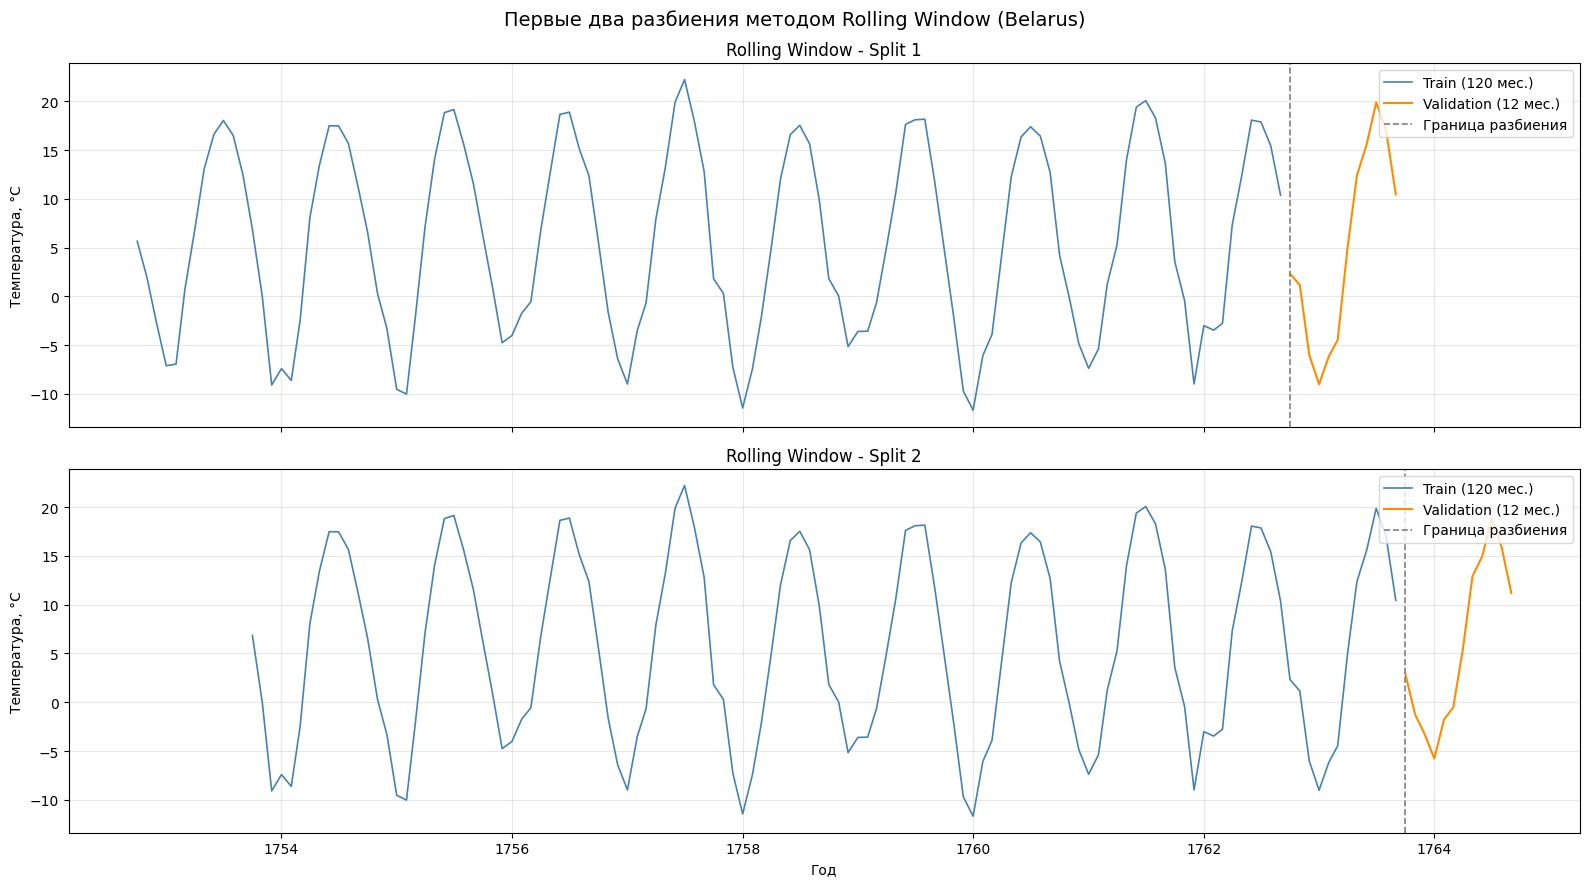

In [161]:
# Визуализация первых двух скользящих окон
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(16, 9),
    sharex=True,
    sharey=True,
)

for split_number, (ax, split) in enumerate(
    zip(axes, rolling_splits[:2], strict=True),
    start=1,
):
    train_window, validation_window = split

    ax.plot(
        train_window.index,
        train_window,
        color="steelblue",
        linewidth=1.2,
        label=f"Train ({len(train_window)} мес.)",
    )

    ax.plot(
        validation_window.index,
        validation_window,
        color="darkorange",
        linewidth=1.5,
        label=f"Validation ({len(validation_window)} мес.)",
    )

    ax.axvline(
        x=validation_window.index.min(),
        color="gray",
        linestyle="--",
        linewidth=1.2,
        label="Граница разбиения",
    )

    ax.set_title(f"Rolling Window - Split {split_number}")
    ax.set_ylabel("Температура, °C")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Год")

fig.suptitle(
    f"Первые два разбиения методом Rolling Window ({COUNTRY})",
    fontsize=14,
)

plt.tight_layout()
plt.show()

#### 3.3.1. Визуализация структуры последовательных разбиений

Для дополнительного анализа механизма скользящего окна визуализируем временные границы первых пяти разбиений.

Данный график позволяет наглядно подтвердить постоянство размера обучающего окна,
фиксированный горизонт прогнозирования и последовательное смещение границ разбиений.

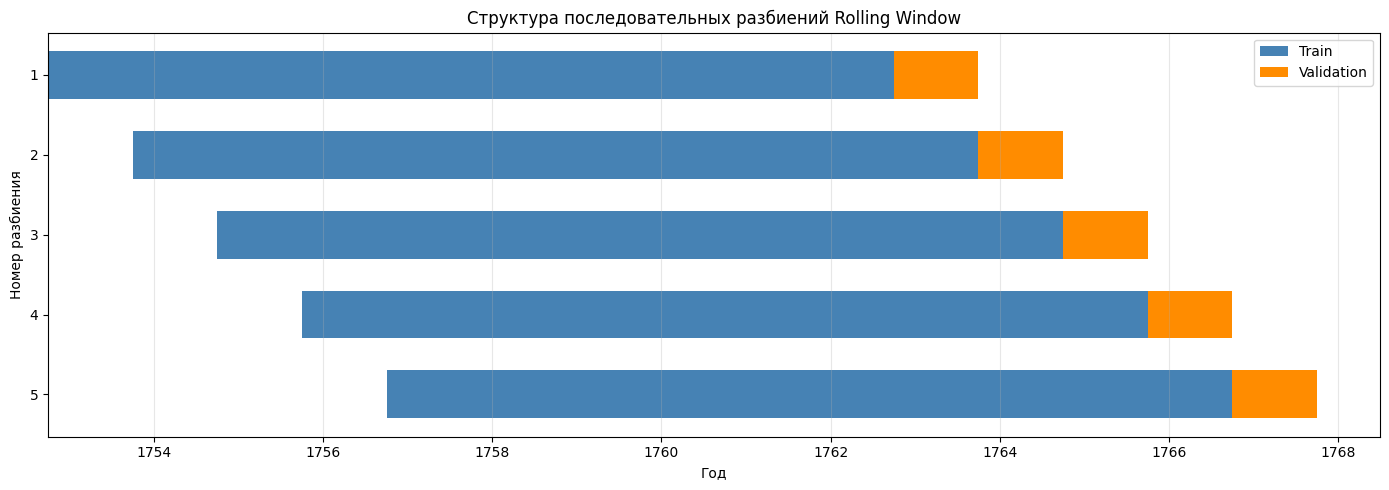

In [162]:
# Визуализация структуры первых пяти скользящих окон
fig, ax = plt.subplots(figsize=(14, 5))

for split_number, (train_window, validation_window) in enumerate(
    rolling_splits[:5],
    start=1,
):
    train_start = train_window.index.min()
    validation_start = validation_window.index.min()

    validation_end = (
        validation_window.index.max() + pd.offsets.MonthBegin(1)
    )

    ax.barh(
        y=split_number,
        width=validation_start - train_start,
        left=train_start,
        height=0.6,
        color="steelblue",
        label="Train" if split_number == 1 else None,
    )

    ax.barh(
        y=split_number,
        width=validation_end - validation_start,
        left=validation_start,
        height=0.6,
        color="darkorange",
        label="Validation" if split_number == 1 else None,
    )

ax.set_title("Структура последовательных разбиений Rolling Window")
ax.set_xlabel("Год")
ax.set_ylabel("Номер разбиения")
ax.set_yticks(range(1, 6))
ax.invert_yaxis()
ax.legend()
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### 3.4. Выводы по этапу Rolling Window

В ходе третьего этапа реализован механизм последовательного разбиения временного ряда
методом скользящего окна (Rolling Window).

**Параметры разбиения:**

- размер обучающего окна -> `120` месяцев
- горизонт прогнозирования -> `12` месяцев
- шаг смещения окна -> `12` месяцев

**Результаты разбиения:**

- на обучающей выборке из `2 504` наблюдений сформировано `198` полных разбиений
- фактическое количество разбиений соответствует аналитически рассчитанному значению
- первое обучающее окно охватывает период с октября 1752 года по сентябрь 1762 года
- первое валидационное окно охватывает период с октября 1762 года по сентябрь 1763 года
- последнее валидационное окно заканчивается в сентябре 1960 года
- оставшиеся `8` месяцев обучающей выборки не образуют полного следующего разбиения

**Проверка корректности разбиений:**

- размеры обучающих и валидационных окон остаются фиксированными
- хронологический порядок и регулярная месячная частота наблюдений сохранены
- обучающие и валидационные наблюдения внутри каждого разбиения не пересекаются
- границы соседних разбиений последовательно смещаются на `12` месяцев
- валидационные окна соседних разбиений не пересекаются
- все разбиения сформированы исключительно на обучающей выборке

Построены графики первых двух разбиений и визуализация структуры первых пяти скользящих окон.

Реализованный механизм может использоваться для последовательного обучения
и валидации прогнозных моделей на различных исторических периодах.

На данном этапе выполнено формирование и исследование временных разбиений.
Обучение моделей на каждом скользящем окне не проводилось.
Финальная тестовая выборка сохранена для итоговой оценки качества прогнозирования.

## 4. Генерация признаков (Feature Engineering)

**Цель этапа**

Преобразовать одномерный временной ряд среднемесячных температур в набор данных
для обучения модели машинного обучения с учетом временной зависимости
и годовой сезонности наблюдений.

На данном этапе необходимо:

- сформировать лаговые признаки `t-1` и `t-12`
- добавить номер календарного месяца
- добавить индикатор зимнего сезона
- обработать начальные наблюдения, для которых отсутствуют лаговые значения
- сохранить ранее определенную границу Holdout-разбиения
- сформировать обучающий и тестовый наборы признаков
- проверить корректность признаков и отсутствие использования будущих наблюдений

### 4.1. Формирование лаговых и календарных признаков

По результатам исследовательского анализа временного ряда выявлена выраженная годовая сезонность температур.

В соответствии с условиями задания формируются следующие признаки:

| Признак | Описание |
|---|---|
| `lag_1` | Температура предыдущего календарного месяца |
| `lag_12` | Температура аналогичного месяца предыдущего года |
| `month` | Порядковый номер календарного месяца (`1–12`) |
| `is_winter` | Индикатор зимнего сезона (`1` для декабря, января и февраля, иначе `0`) |

Целевая переменная -> `AverageTemperature`.

Лаговые признаки определяются следующим образом:

$$
lag_1(t) = y_{t-1}
$$

$$
lag_{12}(t) = y_{t-12}
$$

Для формирования лаговых признаков используется метод `shift()` библиотеки `pandas`.

Регулярная месячная частота подготовленного временного ряда обеспечивает соответствие лагов календарным интервалам.

Календарные признаки определяются непосредственно на основании даты прогнозируемого наблюдения и являются заранее известными.

Для первых `12` наблюдений отсутствует необходимая история для формирования всех лаговых признаков.
Данные наблюдения исключаются из результирующего набора данных без искусственного заполнения лаговых значений.

In [163]:
# Восстановление непрерывной истории наблюдений
temperature_history = pd.concat(
    [train_series, test_series]
)

assert temperature_history.equals(
    prepared_temperature_series
)

# Формирование лаговых и календарных признаков
temperature_features = build_temperature_features(
    temperature_history,
    lags=LAGS,
)

temperature_features.head(12)

,AverageTemperature,lag_1,lag_12,month,is_winter
dt,,,,,
1753-10-01,6.840,12.448,5.644,10,0
1753-11-01,0.024,6.840,1.910,11,0
1753-12-01,-9.095,0.024,-2.712,12,1
1754-01-01,-7.417,-9.095,-7.122,1,1
1754-02-01,-8.626,-7.417,-6.956,2,1
1754-03-01,-2.479,-8.626,0.706,3,0
1754-04-01,8.075,-2.479,6.768,4,0
1754-05-01,13.419,8.075,13.060,5,0
1754-06-01,17.493,13.419,16.615,6,0


In [164]:
# Просмотр последних наблюдений сформированного набора
temperature_features.tail(12)

,AverageTemperature,lag_1,lag_12,month,is_winter
dt,,,,,
2012-09-01,13.680,17.781,13.643,9,0
2012-10-01,7.188,13.680,6.394,10,0
2012-11-01,3.804,7.188,2.271,11,0
2012-12-01,-6.036,3.804,1.196,12,1
2013-01-01,-6.989,-6.036,-4.867,1,1
2013-02-01,-1.969,-6.989,-10.805,2,1
2013-03-01,-4.565,-1.969,1.189,3,0
2013-04-01,6.900,-4.565,8.391,4,0
2013-05-01,16.744,6.900,14.965,5,0


In [165]:
# Основные характеристики сформированного набора данных
print(
    f"Исходное количество наблюдений: "
    f"{len(temperature_history):,}"
)
print(
    f"Количество наблюдений после генерации признаков: "
    f"{len(temperature_features):,}"
)
print(
    f"Исключено начальных наблюдений: "
    f"{len(temperature_history) - len(temperature_features)}"
)
print(
    f"Количество входных признаков: "
    f"{temperature_features.shape[1] - 1}"
)
print(
    f"Начало периода: "
    f"{temperature_features.index.min():%Y-%m-%d}"
)
print(
    f"Конец периода: "
    f"{temperature_features.index.max():%Y-%m-%d}"
)

Исходное количество наблюдений: 3,131
Количество наблюдений после генерации признаков: 3,119
Исключено начальных наблюдений: 12
Количество входных признаков: 4
Начало периода: 1753-10-01
Конец периода: 2013-08-01


In [166]:
# Проверка структуры и типов данных
temperature_features.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3119 entries, 1753-10-01 to 2013-08-01
Freq: MS
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   AverageTemperature  3119 non-null   float64
 1   lag_1               3119 non-null   float64
 2   lag_12              3119 non-null   float64
 3   month               3119 non-null   int32  
 4   is_winter           3119 non-null   int64  
dtypes: float64(3), int32(1), int64(1)
memory usage: 134.0 KB


In [167]:
# Проверка наличия пропущенных значений
temperature_features.isna().sum()

AverageTemperature    0
lag_1                 0
lag_12                0
month                 0
is_winter             0
dtype: int64

### 4.2. Проверка корректности сформированных признаков

Для подтверждения корректности генерации признаков проверим:

- сохранение хронологического порядка наблюдений
- сохранение регулярной месячной частоты
- отсутствие пропущенных и бесконечных значений
- соответствие количества исключенных наблюдений максимальному лагу
- соответствие лаговых значений фактическим температурам предыдущих календарных месяцев
- корректность номера календарного месяца
- корректность индикатора зимнего сезона

Особое внимание уделяется направлению временного смещения лаговых признаков,
для прогнозируемого наблюдения должны использоваться только предшествующие значения температуры.

In [168]:
# Проверка структуры сформированного набора данных
assert isinstance(
    temperature_features.index,
    pd.DatetimeIndex,
)
assert temperature_features.index.is_unique
assert temperature_features.index.is_monotonic_increasing
assert temperature_features.index.freqstr == FREQUENCY

assert temperature_features.notna().all().all()
assert np.isfinite(temperature_features.to_numpy()).all()

assert (
    len(temperature_features)
    == len(temperature_history) - max(LAGS)
)

assert temperature_features.index.equals(
    temperature_history.index[max(LAGS):]
)

# Проверка сохранения значений целевой переменной
pd.testing.assert_series_equal(
    temperature_features[TARGET_COLUMN],
    temperature_history.iloc[max(LAGS):],
)

print("Проверка структуры набора признаков пройдена")

Проверка структуры набора признаков пройдена


In [169]:
# Проверка соответствия лагов историческим температурам
for lag in LAGS:
    historical_dates = (
        temperature_features.index
        - pd.DateOffset(months=lag)
    )

    expected_values = temperature_history.loc[
        historical_dates
    ].to_numpy()

    actual_values = temperature_features[
        f"lag_{lag}"
    ].to_numpy()

    np.testing.assert_array_equal(
        actual_values,
        expected_values,
    )

    assert (
        historical_dates < temperature_features.index
    ).all()

    print(f"Проверка признака lag_{lag} пройдена")

Проверка признака lag_1 пройдена
Проверка признака lag_12 пройдена


In [170]:
# Проверка корректности календарных признаков
np.testing.assert_array_equal(
    temperature_features["month"].to_numpy(),
    temperature_features.index.month.to_numpy(),
)

expected_winter = (
    temperature_features.index.month
    .isin(WINTER_MONTHS)
    .astype(int)
)

np.testing.assert_array_equal(
    temperature_features["is_winter"].to_numpy(),
    expected_winter,
)

assert temperature_features["month"].between(1, 12).all()
assert temperature_features["is_winter"].isin([0, 1]).all()

print("Проверка календарных признаков пройдена")

Проверка календарных признаков пройдена


In [171]:
# Проверка соответствия календарного месяца зимнему сезону
calendar_features = (
    temperature_features[["month", "is_winter"]]
    .drop_duplicates()
    .sort_values("month")
    .reset_index(drop=True)
)

calendar_features

,month,is_winter
0,1,1
1,2,1
2,3,0
3,4,0
4,5,0
5,6,0
6,7,0
7,8,0
8,9,0
9,10,0


### 4.3. Формирование обучающего и тестового наборов признаков

Генерация лаговых признаков выполняется на непрерывной истории наблюдений
с сохранением ранее определенной границы Holdout-разбиения.

Независимая генерация лаговых признаков для обучающей и тестовой выборок
привела бы к необоснованной потере первых `12` тестовых наблюдений,
так как необходимая для них история содержится в обучающей выборке.

Для последующего прогнозирования используется подход One-Step-Ahead Forecasting,
то есть последовательное прогнозирование на один календарный месяц вперед.

При данном подходе:

- модель обучается исключительно на обучающей выборке
- при прогнозировании очередного месяца используются фактические температуры предшествующих месяцев
- после получения фактического наблюдения за очередной месяц оно становится доступным для формирования последующих прогнозов
- параметры обученной модели на тестовой выборке не обновляются
- текущие и будущие значения целевой переменной не используются в качестве входных признаков

Таким образом, использование предшествующих тестовых наблюдений при формировании лаговых признаков
соответствует выбранному протоколу одношагового прогнозирования и не является утечкой данных.

Полученные прогнозы не следует интерпретировать как единый многошаговый прогноз,
сформированный в момент окончания обучающего периода.

Повторное разделение данных в пропорции `80/20` не выполняется.
Обучающий и тестовый наборы признаков формируются по ранее зафиксированным временным границам.

In [172]:
# Формирование наборов признаков по границам Holdout
train_features = temperature_features.loc[
    temperature_features.index < test_series.index.min()
    ].copy()

test_features = temperature_features.loc[
    temperature_features.index >= test_series.index.min()
    ].copy()

print(f"Обучающий набор: {train_features.shape}")
print(f"Тестовый набор: {test_features.shape}")

Обучающий набор: (2492, 5)
Тестовый набор: (627, 5)


In [173]:
# Сравнение характеристик обучающего и тестового наборов
feature_split_statistics = pd.DataFrame(
    {
        "train": {
            "start_date": train_features.index.min(),
            "end_date": train_features.index.max(),
            "observations_count": len(train_features),
            "features_count": train_features.shape[1] - 1,
            "missing_count": train_features.isna().sum().sum(),
        },
        "test": {
            "start_date": test_features.index.min(),
            "end_date": test_features.index.max(),
            "observations_count": len(test_features),
            "features_count": test_features.shape[1] - 1,
            "missing_count": test_features.isna().sum().sum(),
        },
    }
)

feature_split_statistics

,train,test
start_date,1753-10-01 00:00:00,1961-06-01 00:00:00
end_date,1961-05-01 00:00:00,2013-08-01 00:00:00
observations_count,2492,627
features_count,4,4
missing_count,0,0


In [174]:
# Проверка сохранения границ Holdout-разбиения
assert len(train_features) == len(train_series) - max(LAGS)
assert len(test_features) == len(test_series)

assert train_features.index.equals(
    train_series.index[max(LAGS):]
)
assert test_features.index.equals(test_series.index)

assert train_features.index.intersection(
    test_features.index
).empty

assert train_features.index.max() < test_features.index.min()

assert pd.concat(
    [train_features, test_features]
).equals(temperature_features)

pd.testing.assert_series_equal(
    train_features[TARGET_COLUMN],
    train_series.iloc[max(LAGS):],
)

pd.testing.assert_series_equal(
    test_features[TARGET_COLUMN],
    test_series,
)

print("Все проверки границ Holdout-разбиения пройдены")

Все проверки границ Holdout-разбиения пройдены


### 4.4. Проверка лаговых признаков на границе Holdout-разбиения

Для подтверждения корректности формирования тестовых признаков
отдельно проверим первое наблюдение тестовой выборки.

Для прогнозирования температуры июня 1961 года используются:

- `lag_1` -> фактическая температура мая 1961 года
- `lag_12` -> фактическая температура июня 1960 года
- `month` -> `6`
- `is_winter` -> `0`

Оба лаговых значения должны соответствовать наблюдениям обучающей выборки.

Дополнительно проверим переход от использования исключительно обучающей истории
к использованию предшествующих тестовых наблюдений в рамках последовательного одношагового прогнозирования.

In [175]:
# Просмотр наблюдений вблизи границы Holdout
pd.concat(
    [
        train_features.tail(3),
        test_features.head(3),
    ]
)

,AverageTemperature,lag_1,lag_12,month,is_winter
dt,,,,,
1961-03-01,2.912,-1.086,-3.261,3,0
1961-04-01,7.217,2.912,5.855,4,0
1961-05-01,12.003,7.217,12.941,5,0
1961-06-01,18.037,12.003,17.515,6,0
1961-07-01,17.759,18.037,19.155,7,0
1961-08-01,16.437,17.759,16.836,8,0


In [176]:
# Проверка лаговых признаков первого тестового наблюдения
first_test_date = test_features.index.min()

first_test_features = test_features.loc[first_test_date]

for lag in LAGS:
    historical_date = (
        first_test_date - pd.DateOffset(months=lag)
    )

    assert historical_date in train_series.index

    expected_value = train_series.loc[historical_date]
    actual_value = first_test_features[f"lag_{lag}"]

    assert actual_value == expected_value

    print(
        f"lag_{lag}: "
        f"дата = {historical_date:%Y-%m-%d}, "
        f"температура = {actual_value:.3f} °C"
    )

print("Лаги первого тестового наблюдения сформированы корректно")

lag_1: дата = 1961-05-01, температура = 12.003 °C
lag_12: дата = 1960-06-01, температура = 17.515 °C
Лаги первого тестового наблюдения сформированы корректно


In [177]:
# Проверка использования доступной тестовой истории
second_test_date = test_features.index[1]

previous_date = (
    second_test_date - pd.DateOffset(months=1)
)

assert previous_date == first_test_date

assert (
    test_features.loc[second_test_date, "lag_1"]
    == test_series.loc[previous_date]
)

print(
    f"Прогнозируемый месяц: "
    f"{second_test_date:%Y-%m-%d}"
)
print(
    f"Дата предыдущего наблюдения: "
    f"{previous_date:%Y-%m-%d}"
)
print(
    f"Значение lag_1: "
    f"{test_features.loc[second_test_date, 'lag_1']:.3f} °C"
)

Прогнозируемый месяц: 1961-07-01
Дата предыдущего наблюдения: 1961-06-01
Значение lag_1: 18.037 °C


### 4.5. Формирование матриц признаков и целевых переменных

Для последующего обучения модели машинного обучения разделим
подготовленные наборы данных на входные признаки и целевую переменную.

Формируются следующие наборы:

- `X_train` -> входные признаки обучающей выборки
- `y_train` -> фактические температуры обучающей выборки
- `X_test` -> входные признаки тестовой выборки
- `y_test` -> фактические температуры тестовой выборки

В качестве входных признаков используются исключительно `lag_1`, `lag_12`, `month` и `is_winter`.

Целевая переменная `AverageTemperature` не включается в матрицы входных признаков.

Масштабирование признаков на данном этапе не применяется,
так как для используемой далее модели обычной линейной регрессии
без регуляризации оно не является обязательным.

In [178]:
# Определение входных признаков модели
feature_columns = [
    *(f"lag_{lag}" for lag in LAGS),
    "month",
    "is_winter",
]

# Формирование матриц признаков и целевых переменных
X_train = train_features[feature_columns].copy()
y_train = train_features[TARGET_COLUMN].copy()

X_test = test_features[feature_columns].copy()
y_test = test_features[TARGET_COLUMN].copy()

print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_test: {y_test.shape}")

print(f"Входные признаки: {feature_columns}")

X_train: (2492, 4)
y_train: (2492,)
X_test: (627, 4)
y_test: (627,)
Входные признаки: ['lag_1', 'lag_12', 'month', 'is_winter']


In [179]:
# Проверка готовности данных к моделированию
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

assert X_train.columns.equals(X_test.columns)

assert TARGET_COLUMN not in X_train.columns
assert TARGET_COLUMN not in X_test.columns

assert X_train.notna().all().all()
assert X_test.notna().all().all()
assert y_train.notna().all()
assert y_test.notna().all()

assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_test.to_numpy()).all()
assert np.isfinite(y_train.to_numpy()).all()
assert np.isfinite(y_test.to_numpy()).all()

assert X_train.index.intersection(X_test.index).empty
assert X_train.index.max() < X_test.index.min()

print("Все проверки готовности данных к моделированию пройдены")

Все проверки готовности данных к моделированию пройдены


In [180]:
# Просмотр первых строк
# обучающей матрицы признаков
X_train.head()

,lag_1,lag_12,month,is_winter
dt,,,,
1753-10-01,12.448,5.644,10,0
1753-11-01,6.840,1.910,11,0
1753-12-01,0.024,-2.712,12,1
1754-01-01,-9.095,-7.122,1,1
1754-02-01,-7.417,-6.956,2,1


In [181]:
# Просмотр первых строк
# тестовой матрицы признаков
X_test.head()

,lag_1,lag_12,month,is_winter
dt,,,,
1961-06-01,12.003,17.515,6,0
1961-07-01,18.037,19.155,7,0
1961-08-01,17.759,16.836,8,0
1961-09-01,16.437,10.631,9,0
1961-10-01,12.385,6.405,10,0


### 4.6. Выводы по этапу генерации признаков

В ходе четвертого этапа выполнено преобразование одномерного временного ряда
среднемесячных температур в набор данных для обучения прогнозной модели.

**Сформированные признаки:**

- `lag_1` -> температура предыдущего календарного месяца
- `lag_12` -> температура аналогичного месяца предыдущего года
- `month` -> порядковый номер календарного месяца
- `is_winter` -> индикатор зимнего сезона

**Результаты подготовки данных:**

- из `3 131` исходного наблюдения сформировано `3 119` наблюдений с полным набором признаков
- исключены первые `12` наблюдений, для которых отсутствует необходимая история формирования лаговых признаков
- обучающий набор содержит `2 492` наблюдения
- тестовый набор содержит `627` наблюдений
- сохранена ранее определенная граница Holdout-разбиения (`1961-06-01`)
- все тестовые наблюдения сохранены
- пропущенные и бесконечные значения отсутствуют

**Проверка корректности признаков:**

- подтверждено соответствие лаговых признаков фактическим температурам предыдущих календарных месяцев
- подтверждено использование исключительно предшествующих наблюдений при формировании лагов
- проверена корректность календарных признаков
- подтверждено отсутствие пересечений обучающей и тестовой выборок
- целевая переменная исключена из матриц входных признаков

Для последующего моделирования сформированы матрицы `X_train`, `X_test` и соответствующие целевые переменные `y_train`, `y_test`.

В рамках выбранного протокола One-Step-Ahead Forecasting предшествующие фактические наблюдения
тестового периода используются в качестве доступной истории без обновления параметров обученной модели.

Сформированные наборы данных готовы к обучению модели линейной регрессии и последующей оценке качества прогнозирования.

## 5. Обучение модели и прогнозирование

**Цель этапа**

Обучить базовую модель прогнозирования среднемесячных температур на основе сформированных лаговых
и календарных признаков и получить прогнозы для отложенной тестовой выборки.

На данном этапе необходимо:

- обучить модель линейной регрессии на обучающей выборке
- исследовать полученные коэффициенты модели
- сформировать прогнозы для тестового периода
- проверить корректность полученных прогнозов
- визуализировать фактические и прогнозные значения температуры

### 5.1. Обучение модели линейной регрессии

В качестве базовой прогнозной модели используется `LinearRegression` из библиотеки `scikit-learn`.

Модель описывает линейную зависимость целевой переменной от лаговых и календарных признаков:

$$
\hat{y}_t = \beta_0 + \beta_1 y_{t-1} + \beta_2 y_{t-12}
+ \beta_3 month_t + \beta_4 is\_winter_t
$$

где:

- $\hat{y}_t$ -> прогнозируемая среднемесячная температура
- $\beta_0$ -> свободный член модели
- $\beta_1, \ldots, \beta_4$ -> коэффициенты модели
- $y_{t-1}$ -> температура предыдущего месяца
- $y_{t-12}$ -> температура аналогичного месяца предыдущего года
- $month_t$ -> номер календарного месяца
- $is\_winter_t$ -> индикатор зимнего сезона

Коэффициенты модели определяются методом наименьших квадратов (Ordinary Least Squares, OLS).

Обучение выполняется исключительно на данных `X_train` и `y_train`.
Тестовая выборка не используется для определения коэффициентов модели.

Масштабирование признаков и подбор гиперпараметров не выполняются,
так как в рамках задания достаточно базовой модели линейной регрессии без регуляризации.

In [182]:
# Инициализация и обучение модели линейной регрессии
model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 0.3 , 0.66,-0.29,-2.04]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['lag_1','lag_12','month','is_winter']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.647
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,4


In [183]:
# Проверка параметров обученной модели
assert model.n_features_in_ == len(feature_columns)

np.testing.assert_array_equal(
    model.feature_names_in_,
    X_train.columns.to_numpy(),
)

assert np.isfinite(model.coef_).all()
assert np.isfinite(model.intercept_)

print(f"Модель: {type(model).__name__}")
print(f"Количество обучающих наблюдений: {len(X_train):,}")
print(f"Количество входных признаков: {model.n_features_in_}")
print("Обучение модели завершено")

Модель: LinearRegression
Количество обучающих наблюдений: 2,492
Количество входных признаков: 4
Обучение модели завершено


### 5.2. Анализ коэффициентов обученной модели

Для исследования сформированной линейной зависимости рассмотрим свободный член и коэффициенты обученной модели.

Коэффициент каждого признака характеризует изменение прогнозируемой температуры
при увеличении соответствующего признака на одну единицу при прочих равных условиях.

Поскольку признаки имеют различные единицы измерения и диапазоны значений,
абсолютные значения коэффициентов не следует непосредственно интерпретировать как сравнительную важность признаков.

Кроме того, лаговые и календарные признаки могут быть взаимосвязаны из-за сезонной структуры временного ряда.
Полученные коэффициенты характеризуют зависимости внутри обученной модели
и не устанавливают причинно-следственные связи.

In [184]:
# Формирование таблицы коэффициентов модели
model_coefficients = pd.DataFrame(
    {
        "feature": X_train.columns,
        "coefficient": model.coef_,
    }
).set_index("feature")

model_coefficients.round(6)

,coefficient
feature,
lag_1,0.295293
lag_12,0.661570
month,-0.290655
is_winter,-2.038237


In [185]:
# Свободный член модели
print(f"Свободный член (intercept): {model.intercept_:.6f}")

Свободный член (intercept): 2.646775


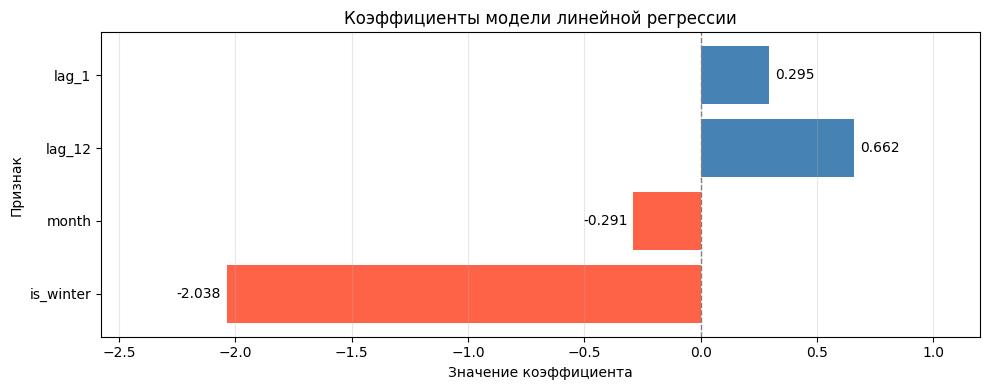

In [186]:
# Визуализация коэффициентов линейной регрессии
fig, ax = plt.subplots(figsize=(10, 4))

coefficient_colors = [
    "steelblue" if coefficient >= 0 else "tomato"
    for coefficient in model_coefficients["coefficient"]
]

bars = ax.barh(
    model_coefficients.index,
    model_coefficients["coefficient"],
    color=coefficient_colors,
)

ax.bar_label(
    bars,
    fmt="%.3f",
    padding=4,
)

ax.axvline(
    x=0,
    color="gray",
    linestyle="--",
    linewidth=1,
)

ax.set_title("Коэффициенты модели линейной регрессии")
ax.set_xlabel("Значение коэффициента")
ax.set_ylabel("Признак")
ax.invert_yaxis()
ax.margins(x=0.2)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### 5.3. Прогнозирование на тестовой выборке

Для оценки прогнозной способности обученной модели сформируем прогнозы среднемесячных температур на отложенной тестовой выборке.

Прогнозирование выполняется в соответствии с ранее определенным протоколом One-Step-Ahead Forecasting.

Для каждого прогнозируемого месяца используются фактические значения температуры предыдущего месяца
и аналогичного месяца предыдущего года, а также заранее известные календарные признаки.

Модель обучается однократно на обучающей выборке. В течение тестового периода ее коэффициенты остаются неизменными.

Поскольку лаговые признаки сформированы исключительно на основании предшествующих наблюдений,
векторизованное получение прогнозов методом `predict()` эквивалентно последовательному одношаговому
прогнозированию при фиксированных параметрах модели.

Полученные прогнозы не являются единым многошаговым прогнозом на весь тестовый период,
сформированным в момент окончания обучающей выборки.

In [187]:
# Получение прогнозов для тестового периода
y_pred = pd.Series(
    model.predict(X_test),
    index=X_test.index,
    name="predicted_temperature",
)

print(f"Количество тестовых наблюдений: {len(y_test):,}")
print(f"Количество прогнозов: {len(y_pred):,}")

Количество тестовых наблюдений: 627
Количество прогнозов: 627


In [188]:
# Проверка корректности сформированных прогнозов
assert len(y_pred) == len(y_test)
assert y_pred.index.equals(y_test.index)

assert y_pred.index.is_unique
assert y_pred.index.is_monotonic_increasing
assert y_pred.index.freqstr == FREQUENCY

assert y_pred.notna().all()
assert np.isfinite(y_pred.to_numpy()).all()

assert y_pred.index.min() == test_series.index.min()
assert y_pred.index.max() == test_series.index.max()

print("Все проверки корректности прогнозов пройдены")

Все проверки корректности прогнозов пройдены


In [189]:
# Сопоставление фактических и прогнозных температур
forecast_results = pd.DataFrame(
    {
        "actual_temperature": y_test,
        "predicted_temperature": y_pred,
    }
)

forecast_results.head(12).round(3)

,actual_temperature,predicted_temperature
dt,,
1961-06-01,18.037,16.035
1961-07-01,17.759,18.611
1961-08-01,16.437,16.704
1961-09-01,12.385,11.918
1961-10-01,7.547,7.635
1961-11-01,1.569,3.124
1961-12-01,-5.462,-1.123
1962-01-01,-2.525,-4.556
1962-02-01,-5.252,-1.437


In [190]:
# Просмотр последних прогнозов тестового периода
forecast_results.tail(12).round(3)

,actual_temperature,predicted_temperature
dt,,
2012-09-01,13.680,14.307
2012-10-01,7.188,8.010
2012-11-01,3.804,3.075
2012-12-01,-6.036,-0.965
2013-01-01,-6.989,-4.684
2013-02-01,-1.969,-9.185
2013-03-01,-4.565,1.980
2013-04-01,6.900,5.687
2013-05-01,16.744,13.131


In [191]:
# Основные характеристики фактических и прогнозных температур
forecast_results.describe().round(3)

,actual_temperature,predicted_temperature
count,627.000,627.000
mean,6.554,6.524
std,8.962,8.563
min,-16.164,-12.798
25%,-0.828,-1.229
50%,7.024,7.109
75%,15.221,14.683
max,22.811,21.272


### 5.4. Визуализация результатов прогнозирования

Для предварительной качественной оценки прогнозов сравним фактические
и прогнозные значения среднемесячной температуры на тестовом периоде.

Визуальный анализ позволит определить, насколько модель воспроизводит сезонные колебания температур,
амплитуду наблюдаемых значений и общую динамику временного ряда.

#### 5.4.1. Прогнозы за весь тестовый период

Построим общий график фактических и прогнозных температур для всех `627` наблюдений
тестовой выборки за период с июня 1961 года по август 2013 года.

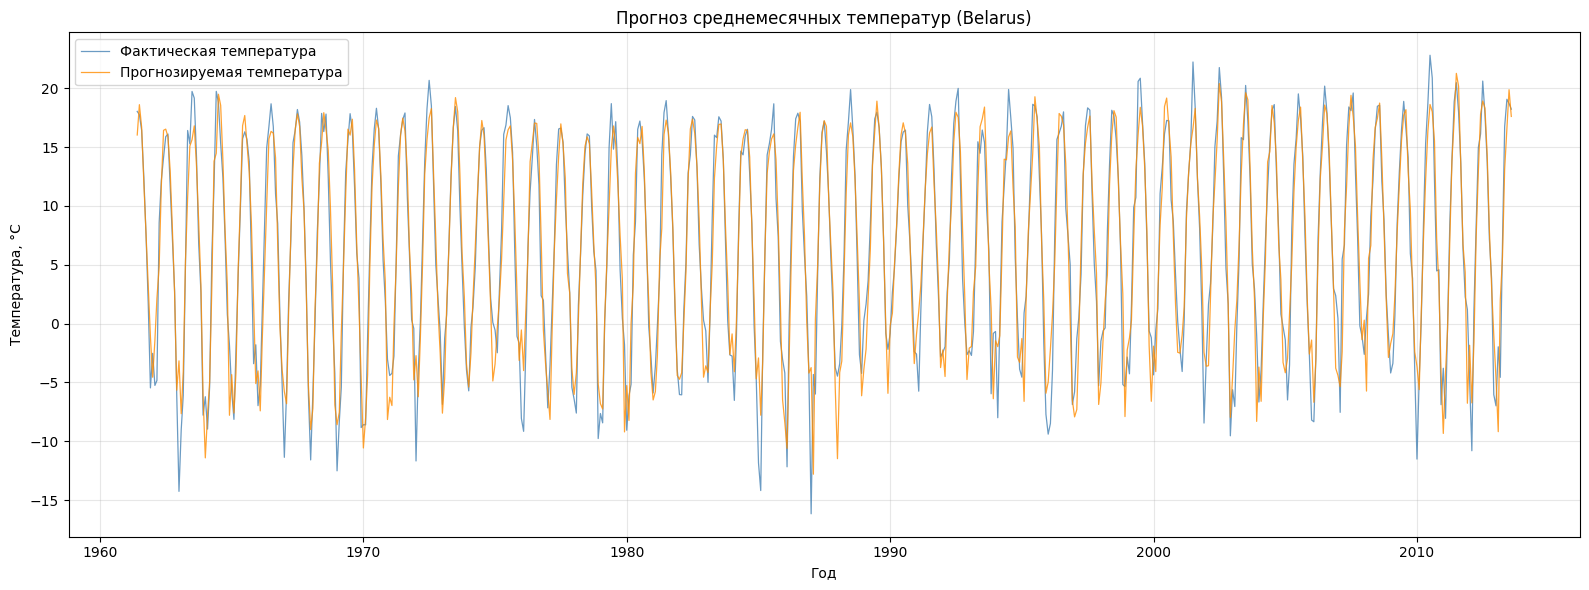

In [192]:
# Сравнение фактических и прогнозных температур
fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(
    forecast_results.index,
    forecast_results["actual_temperature"],
    color="steelblue",
    linewidth=0.9,
    alpha=0.8,
    label="Фактическая температура",
)

ax.plot(
    forecast_results.index,
    forecast_results["predicted_temperature"],
    color="darkorange",
    linewidth=0.9,
    alpha=0.8,
    label="Прогнозируемая температура",
)

ax.set_title(
    f"Прогноз среднемесячных температур ({COUNTRY})"
)
ax.set_xlabel("Год")
ax.set_ylabel("Температура, °C")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### 5.4.2. Детализация прогнозов на отдельном временном интервале

Вследствие значительной продолжительности тестового периода отдельные сезонные циклы
и расхождения между фактическими и прогнозными температурами сложно различить на общем графике.

Для более детального анализа визуализируем первые `36` месяцев тестовой выборки, соответствующие трем полным годовым циклам.

Интервал выбран по фиксированному количеству начальных наблюдений, независимо от величины ошибок прогнозирования.

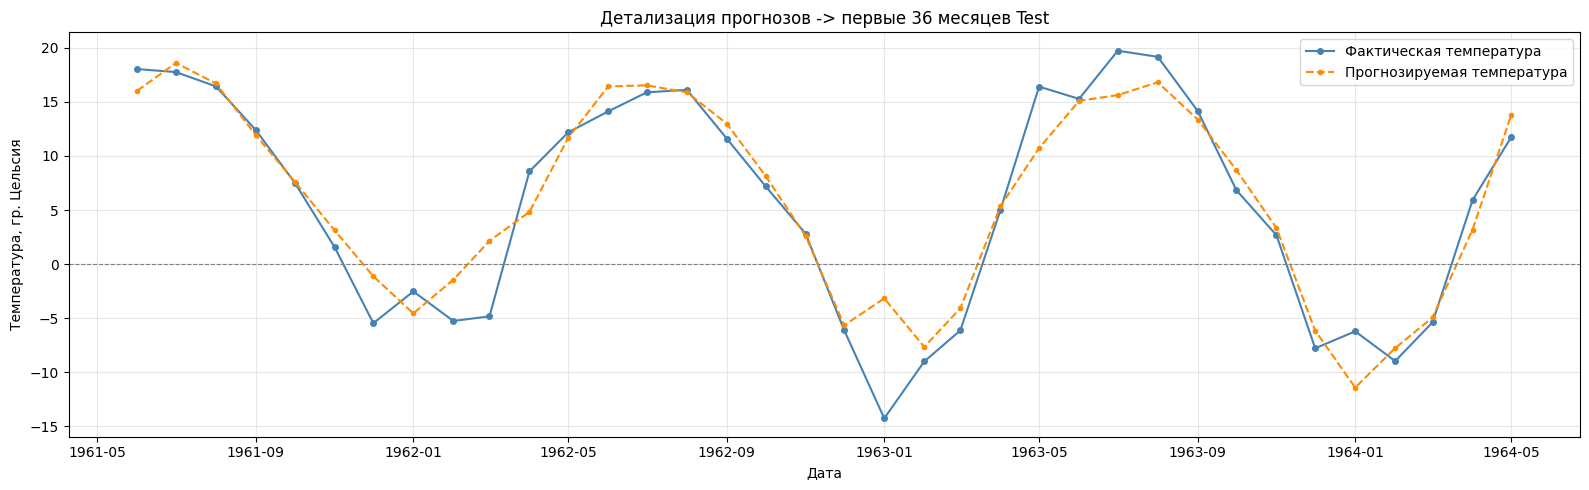

In [193]:
# Выделение первых трех лет тестового периода
forecast_detail = forecast_results.head(36)

fig, ax = plt.subplots(figsize=(16, 5))

ax.plot(
    forecast_detail.index,
    forecast_detail["actual_temperature"],
    color="steelblue",
    linewidth=1.5,
    marker="o",
    markersize=4,
    label="Фактическая температура",
)

ax.plot(
    forecast_detail.index,
    forecast_detail["predicted_temperature"],
    color="darkorange",
    linewidth=1.5,
    linestyle="--",
    marker="o",
    markersize=3,
    label="Прогнозируемая температура",
)

ax.axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=0.8,
)

ax.set_title("Детализация прогнозов -> первые 36 месяцев Test")
ax.set_xlabel("Дата")
ax.set_ylabel("Температура, гр. Цельсия")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### 5.4.3. Сопоставление фактических и прогнозных температур

Для дополнительного анализа качества прогнозов построим диаграмму рассеяния фактических и прогнозных температур.

На горизонтальной оси отображаются фактические значения температуры, на вертикальной прогнозные.

Диагональная линия соответствует идеальному прогнозированию:

$$
\hat{y}_t = y_t
$$

Отклонения точек от диагонали характеризуют ошибки прогнозирования:

- точки выше диагонали соответствуют завышенным прогнозам
- точки ниже диагонали соответствуют заниженным прогнозам

Диаграмма позволяет предварительно оценить наличие систематических отклонений
и особенности прогнозирования температур в различных диапазонах значений.

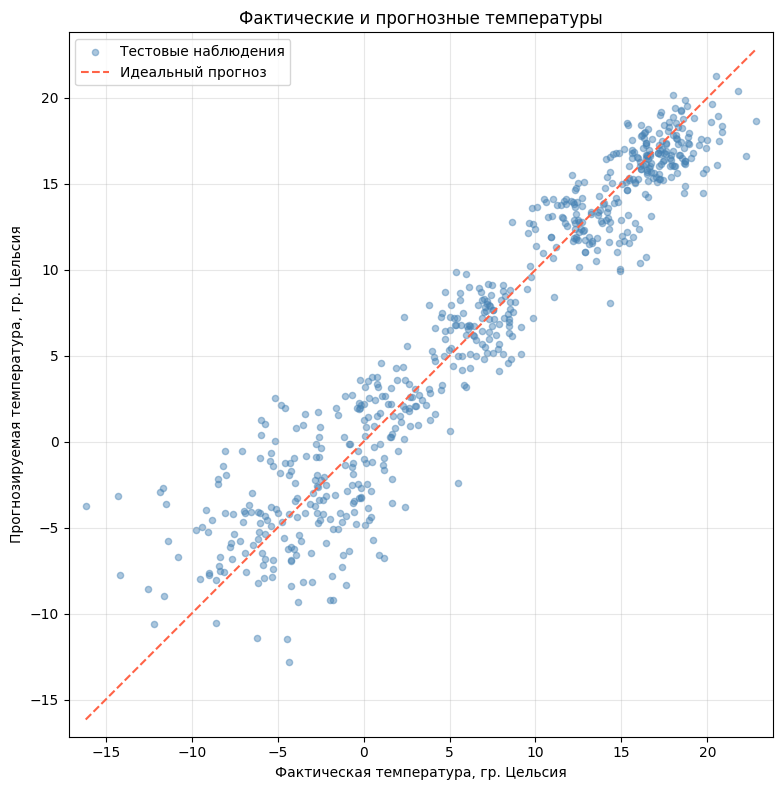

In [194]:
# Сопоставление фактических и прогнозных температур
fig, ax = plt.subplots(figsize=(8, 8))

temperature_min = min(y_test.min(), y_pred.min())
temperature_max = max(y_test.max(), y_pred.max())

ax.scatter(
    y_test,
    y_pred,
    color="steelblue",
    alpha=0.45,
    s=20,
    label="Тестовые наблюдения",
)

ax.plot(
    [temperature_min, temperature_max],
    [temperature_min, temperature_max],
    color="tomato",
    linestyle="--",
    linewidth=1.5,
    label="Идеальный прогноз",
)

ax.set_xlim(temperature_min - 1, temperature_max + 1)
ax.set_ylim(temperature_min - 1, temperature_max + 1)
ax.set_aspect("equal", adjustable="box")

ax.set_title("Фактические и прогнозные температуры")
ax.set_xlabel("Фактическая температура, гр. Цельсия")
ax.set_ylabel("Прогнозируемая температура, гр. Цельсия")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 5.5. Выводы по этапу обучения модели и прогнозирования

В ходе пятого этапа выполнено обучение базовой модели линейной регрессии (`LinearRegression`)
и сформированы прогнозы среднемесячных температур для отложенной тестовой выборки.

**Параметры моделирования:**

- модель обучена на `2 492` наблюдениях с использованием четырех лаговых и календарных признаков
- обучение выполнено исключительно на обучающей выборке
- масштабирование признаков и подбор гиперпараметров не применялись
- прогнозирование выполнено в соответствии с протоколом One-Step-Ahead Forecasting
- параметры модели в течение тестового периода не обновлялись

**Результаты обучения:**

Получены следующие коэффициенты линейной регрессии:

| Признак | Коэффициент |
|---|---:|
| `lag_1` | 0.295293 |
| `lag_12` | 0.661570 |
| `month` | -0.290655 |
| `is_winter` | -2.038237 |

Свободный член модели составляет `2.646775`.

При прочих равных условиях модель демонстрирует более высокую чувствительность
к изменению температуры аналогичного месяца предыдущего года (`lag_12`),
чем к изменению температуры предыдущего месяца (`lag_1`).

Данный результат согласуется с выявленной ранее выраженной годовой сезонностью временного ряда.

**Результаты прогнозирования:**

- сформировано `627` прогнозов для всех наблюдений тестового периода с июня 1961 года по август 2013 года
- временные индексы прогнозных и фактических значений полностью совпадают
- пропущенные и бесконечные значения в прогнозах отсутствуют
- средняя фактическая температура составляет `6,554 гр. Цельсия`, средняя прогнозная `6,524 гр. Цельсия`
- стандартное отклонение прогнозных температур (`8,563 гр. Цельсия`) немного меньше стандартного отклонения
  фактических температур (`8,962 гр. Цельсия`)
- диапазон прогнозируемых температур уже диапазона фактических наблюдений,
  что свидетельствует о некотором сглаживании температурных колебаний

Построены графики фактических и прогнозных температур за весь тестовый период,
детализация первых трех годовых циклов и диаграмма рассеяния фактических и прогнозных значений.

## 6. Оценка качества прогнозирования

**Цель этапа**

Выполнить количественную оценку качества прогнозирования среднемесячных температур
на отложенной тестовой выборке, сравнить результаты линейной регрессии
с базовым сезонным алгоритмом и исследовать особенности ошибок прогнозирования.

На данном этапе необходимо:

- рассчитать метрики MAE, RMSE и MAPE
- оценить применимость MAPE к прогнозированию температуры в градусах Цельсия
- сформировать прогнозы базового сезонного алгоритма (Seasonal Naive Baseline)
- сравнить качество прогнозирования двух подходов
- исследовать распределение ошибок прогнозирования
- проанализировать зависимость качества прогнозов от календарного месяца
- сформулировать итоговые выводы по результатам моделирования

### 6.1. Метрики качества прогнозирования

Для количественной оценки качества прогнозов используются следующие метрики.

**MAE (Mean Absolute Error)** -> средняя абсолютная ошибка:

$$
MAE = \frac{1}{n}\sum_{t=1}^{n}|y_t-\hat{y}_t|
$$

**RMSE (Root Mean Squared Error)** -> корень из средней квадратичной ошибки:

$$
RMSE = \sqrt{\frac{1}{n}\sum_{t=1}^{n}(y_t-\hat{y}_t)^2}
$$

**MAPE (Mean Absolute Percentage Error)** -> средняя абсолютная процентная ошибка:

$$
MAPE = \frac{100\%}{n}\sum_{t=1}^{n}
\left|\frac{y_t-\hat{y}_t}{y_t}\right|
$$

где:

- $n$ -> количество оцениваемых наблюдений
- $y_t$ -> фактическая температура
- $\hat{y}_t$ -> прогнозируемая температура

Метрики MAE и RMSE выражаются в градусах Цельсия. MAPE выражается в процентах.

Для всех трех метрик меньшие значения соответствуют меньшим ошибкам прогнозирования.

В качестве основных метрик оценки используются MAE и RMSE.
MAPE рассчитывается в соответствии с условиями задания,
однако ее интерпретация ограничена наличием отрицательных и близких к нулю температур,
а также отсутствием естественного абсолютного нуля в шкале Цельсия.


#### 6.1.1. Диагностика применимости MAPE

Перед расчетом метрик проверим наличие нулевых и близких к нулю фактических температур
непосредственно в тестовой выборке.

In [195]:
# Диагностика применимости MAPE на тестовой выборке
mape_diagnostics = pd.Series(
    {
        "observations_count": len(y_test),
        "negative_count": y_test.lt(0).sum(),
        "zero_count": y_test.eq(0).sum(),
        "near_zero_count": y_test.abs().lt(1).sum(),
        "min_absolute_temperature": y_test.abs().min(),
    },
    name="value",
)

mape_diagnostics

observations_count          627.000
negative_count              180.000
zero_count                    0.000
near_zero_count              55.000
min_absolute_temperature      0.004
Name: value, dtype: float64

In [196]:
# Доля близких к нулю температур в тестовой выборке
near_zero_ratio = y_test.abs().lt(1).mean()

print(f"Доля близких к нулю температур: {near_zero_ratio:.2%}")

assert not y_test.eq(0).any(), (
    "MAPE не определена при нулевых фактических температурах"
)

Доля близких к нулю температур: 8.77%


#### 6.1.2. Расчет метрик линейной регрессии

Рассчитаем метрики качества прогнозирования обученной модели линейной регрессии
на всех `627` наблюдениях отложенной тестовой выборки.

Фактические и прогнозные температуры сопоставляются по временным индексам.

In [197]:
# Расчет метрик качества линейной регрессии
linear_regression_metrics = calculate_forecast_metrics(
    y_test,
    y_pred,
)

pd.Series(
    linear_regression_metrics,
    name="Linear Regression",
).to_frame().round(4)

,Linear Regression
MAE,2.0319
RMSE,2.7079
MAPE,228.2554


In [198]:
# Проверка корректности рассчитанных метрик
assert all(
    np.isfinite(value) and value >= 0
    for value in linear_regression_metrics.values()
)

assert (
    linear_regression_metrics["RMSE"]
    >= linear_regression_metrics["MAE"]
)

print("Проверка корректности метрик пройдена")

Проверка корректности метрик пройдена


### 6.2. Базовый сезонный алгоритм (Seasonal Naive Baseline)

Для дополнительной оценки эффективности линейной регрессии используется
простой сезонный алгоритм прогнозирования.

В качестве прогноза температуры текущего месяца используется
фактическая температура аналогичного месяца предыдущего года:

$$
\hat{y}_t^{baseline} = y_{t-12}
$$

Данный подход не требует обучения модели и учитывает выявленную годовую сезонность временного ряда.

Прогнозные значения Seasonal Naive формируются на основе ранее рассчитанного признака `lag_12`.

Оценка выполняется на той же тестовой выборке и в рамках того же протокола доступности исторических наблюдений,
что и для линейной регрессии.

Использование базового алгоритма позволяет определить,
обеспечивает ли обученная модель снижение ошибок прогнозирования относительно простого сезонного правила.

In [199]:
# Формирование прогнозов базового сезонного алгоритма
y_baseline_pred = X_test["lag_12"].rename(
    "baseline_temperature"
)

assert y_baseline_pred.index.equals(y_test.index)
assert len(y_baseline_pred) == len(y_test)
assert np.isfinite(y_baseline_pred.to_numpy()).all()

# Расчет метрик качества Seasonal Naive
seasonal_naive_metrics = calculate_forecast_metrics(
    y_test,
    y_baseline_pred,
)

pd.Series(
    seasonal_naive_metrics,
    name="Seasonal Naive",
).to_frame().round(4)

,Seasonal Naive
MAE,2.2456
RMSE,3.0015
MAPE,253.4956


In [200]:
# Дополнение результатов прогнозами базового алгоритма
forecast_results["baseline_temperature"] = y_baseline_pred

forecast_results.head(12).round(3)

,actual_temperature,predicted_temperature,baseline_temperature
dt,,,
1961-06-01,18.037,16.035,17.515
1961-07-01,17.759,18.611,19.155
1961-08-01,16.437,16.704,16.836
1961-09-01,12.385,11.918,10.631
1961-10-01,7.547,7.635,6.405
1961-11-01,1.569,3.124,2.185
1961-12-01,-5.462,-1.123,1.955
1962-01-01,-2.525,-4.556,-4.929
1962-02-01,-5.252,-1.437,-1.086


### 6.3. Сравнение качества прогнозирования

Для сопоставления качества прогнозов сформируем общую таблицу метрик
линейной регрессии и базового сезонного алгоритма.

Оба подхода оцениваются на одинаковом наборе фактических наблюдений.

Дополнительно рассчитаем относительное снижение ошибок линейной регрессии
по сравнению с Seasonal Naive Baseline:

$$
Improvement = \frac{Error_{baseline}-Error_{model}}
{Error_{baseline}}\cdot 100\%
$$

Положительное значение соответствует снижению ошибки относительно базового алгоритма,
отрицательное соответствует увеличению ошибки.

Основные выводы о качестве прогнозирования будут сформулированы на основании MAE и RMSE с учетом ограничений метрики MAPE.

In [201]:
# Формирование общей таблицы метрик
metrics_comparison = pd.DataFrame(
    {
        "Linear Regression": linear_regression_metrics,
        "Seasonal Naive": seasonal_naive_metrics,
    }
).T

metrics_comparison.index.name = "model"

metrics_comparison.round(4)

,MAE,RMSE,MAPE
model,,,
Linear Regression,2.0319,2.7079,228.2554
Seasonal Naive,2.2456,3.0015,253.4956


In [202]:
# Расчет относительного снижения ошибок
baseline_metrics = metrics_comparison.loc["Seasonal Naive"]
model_metrics = metrics_comparison.loc["Linear Regression"]

assert baseline_metrics.gt(0).all()

metrics_improvement = (
    (baseline_metrics - model_metrics)
    / baseline_metrics
    * 100
).rename("improvement_percent")

metrics_improvement.to_frame().round(2)

,improvement_percent
MAE,9.51
RMSE,9.78
MAPE,9.96


In [203]:
# Выделение минимальных значений метрик
metrics_comparison.style.format(
    {
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "MAPE": "{:.2f}%",
    }
).highlight_min(
    axis=0,
    color="lightgreen",
)

,MAE,RMSE,MAPE
model,,,
Linear Regression,2.0319,2.7079,228.26%
Seasonal Naive,2.2456,3.0015,253.50%


#### 6.3.1. Визуализация результатов сравнения

Для наглядного сравнения качества прогнозирования построим столбчатые диаграммы значений MAE, RMSE и MAPE для обоих алгоритмов.

Метрики визуализируются отдельно, поскольку имеют различные масштабы и единицы измерения.

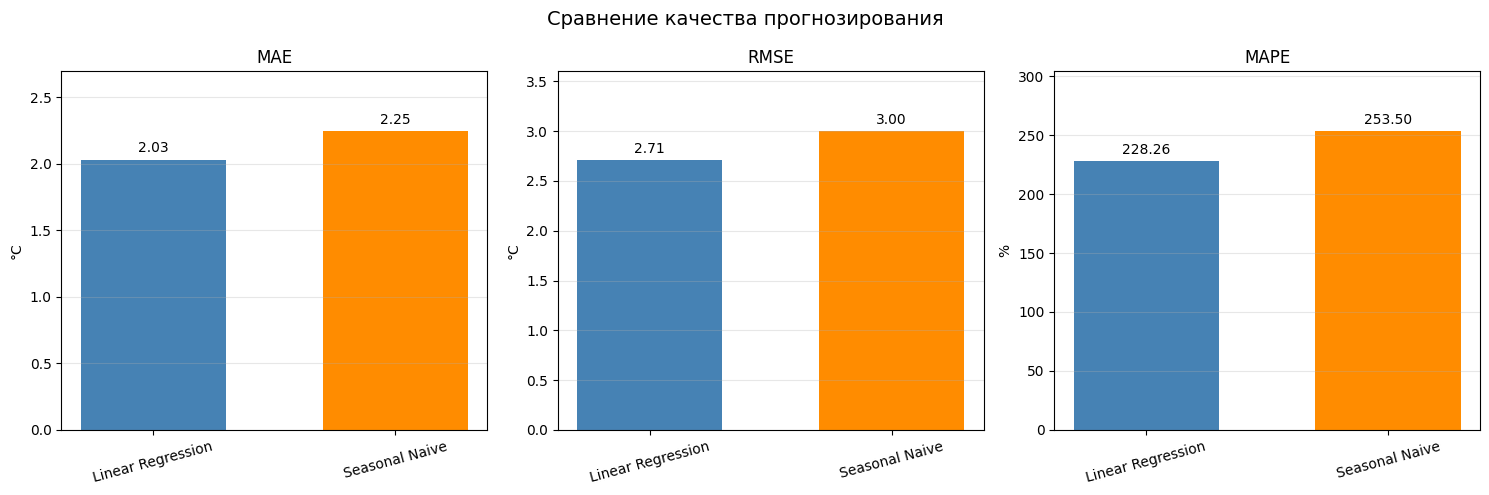

In [204]:
# Визуализация сравнения метрик качества
fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(15, 5),
)

metric_units = {
    "MAE": "°C",
    "RMSE": "°C",
    "MAPE": "%",
}

for ax, metric in zip(
    axes,
    metrics_comparison.columns,
    strict=True,
):
    bars = ax.bar(
        metrics_comparison.index,
        metrics_comparison[metric],
        color=["steelblue", "darkorange"],
        width=0.6,
    )

    ax.bar_label(
        bars,
        fmt="%.2f",
        padding=3,
    )

    ax.set_title(metric)
    ax.set_ylabel(metric_units[metric])
    ax.set_ylim(
        0,
        metrics_comparison[metric].max() * 1.2,
    )
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Сравнение качества прогнозирования",
    fontsize=14,
)

plt.tight_layout()
plt.show()

#### 6.3.2. Сравнение прогнозов на отдельном временном интервале

Для качественного сравнения двух подходов визуализируем фактические температуры
и прогнозы обоих алгоритмов за первые `36` месяцев тестового периода.

Используется тот же временной интервал, который рассматривался при исследовании прогнозов линейной регрессии.

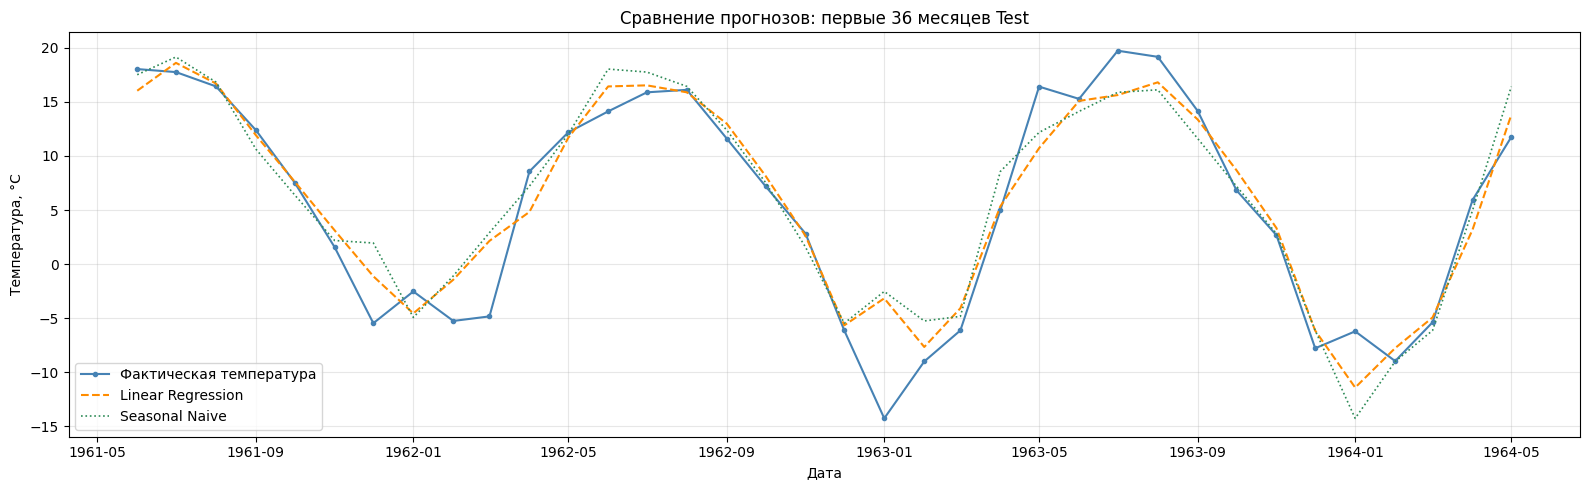

In [205]:
# Сравнение прогнозов линейной и базовой моделей
forecast_comparison = forecast_results.head(36)

fig, ax = plt.subplots(figsize=(16, 5))

ax.plot(
    forecast_comparison.index,
    forecast_comparison["actual_temperature"],
    color="steelblue",
    linewidth=1.5,
    marker="o",
    markersize=3,
    label="Фактическая температура",
)

ax.plot(
    forecast_comparison.index,
    forecast_comparison["predicted_temperature"],
    color="darkorange",
    linewidth=1.5,
    linestyle="--",
    label="Linear Regression",
)

ax.plot(
    forecast_comparison.index,
    forecast_comparison["baseline_temperature"],
    color="seagreen",
    linewidth=1.2,
    linestyle=":",
    label="Seasonal Naive",
)

ax.set_title("Сравнение прогнозов: первые 36 месяцев Test")
ax.set_xlabel("Дата")
ax.set_ylabel("Температура, °C")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 6.4. Анализ ошибок прогнозирования

Агрегированные метрики характеризуют общее качество прогнозирования,
но не отражают распределение ошибок во времени и возможное наличие систематических отклонений.

Для дополнительного исследования рассчитаем остатки прогнозной модели (residuals):

$$
e_t = y_t-\hat{y}_t
$$

При выбранном определении остатка:

- положительные значения соответствуют заниженным прогнозам
- отрицательные значения соответствуют завышенным прогнозам
- значения, близкие к нулю, соответствуют более точным прогнозам

#### 6.4.1. Формирование и описательная статистика остатков

Рассчитаем остатки, абсолютные ошибки и основные статистические характеристики ошибок линейной регрессии.

In [206]:
# Расчет остатков прогнозной модели
forecast_results["residual"] = y_test - y_pred

forecast_results["absolute_error"] = (
    forecast_results["residual"].abs()
)

forecast_results["squared_error"] = (
    forecast_results["residual"].pow(2)
)

forecast_results.head(12).round(3)

,actual_temperature,predicted_temperature,baseline_temperature,residual,absolute_error,squared_error
dt,,,,,,
1961-06-01,18.037,16.035,17.515,2.002,2.002,4.009
1961-07-01,17.759,18.611,19.155,-0.852,0.852,0.725
1961-08-01,16.437,16.704,16.836,-0.267,0.267,0.071
1961-09-01,12.385,11.918,10.631,0.467,0.467,0.218
1961-10-01,7.547,7.635,6.405,-0.088,0.088,0.008
1961-11-01,1.569,3.124,2.185,-1.555,1.555,2.417
1961-12-01,-5.462,-1.123,1.955,-4.339,4.339,18.830
1962-01-01,-2.525,-4.556,-4.929,2.031,2.031,4.125
1962-02-01,-5.252,-1.437,-1.086,-3.815,3.815,14.555


In [207]:
# Описательная статистика остатков
forecast_results["residual"].describe().round(4)

count    627.0000
mean       0.0296
std        2.7099
min      -12.4251
25%       -1.5323
50%        0.1485
75%        1.6558
max        8.4779
Name: residual, dtype: float64

In [208]:
# Дополнительные характеристики ошибок прогнозирования
residuals = forecast_results["residual"]

error_statistics = pd.Series(
    {
        "mean_error": residuals.mean(),
        "median_error": residuals.median(),
        "std_error": residuals.std(),
        "max_absolute_error": (
            forecast_results["absolute_error"].max()
        ),
        "underestimated_count": residuals.gt(0).sum(),
        "overestimated_count": residuals.lt(0).sum(),
        "exact_predictions_count": residuals.eq(0).sum(),
    },
    name="value",
)

error_statistics.round(4)

mean_error                   0.0296
median_error                 0.1485
std_error                    2.7099
max_absolute_error          12.4251
underestimated_count       325.0000
overestimated_count        302.0000
exact_predictions_count      0.0000
Name: value, dtype: float64

In [209]:
# Независимая проверка расчета метрик качества
np.testing.assert_allclose(
    forecast_results["absolute_error"].mean(),
    linear_regression_metrics["MAE"],
)

np.testing.assert_allclose(
    np.sqrt(
        forecast_results["squared_error"].mean()
    ),
    linear_regression_metrics["RMSE"],
)

np.testing.assert_allclose(
    (residuals / y_test).abs().mean() * 100,
    linear_regression_metrics["MAPE"],
)

print("Метрики MAE, RMSE и MAPE подтверждены независимым расчетом")

Метрики MAE, RMSE и MAPE подтверждены независимым расчетом


#### 6.4.2. Динамика остатков во времени

Для исследования стабильности прогнозирования построим график остатков модели за весь тестовый период.

Дополнительно рассчитаем скользящую среднюю абсолютную ошибку с окном `12` месяцев.

Данный показатель позволит предварительно оценить изменение качества прогнозирования
на различных исторических интервалах.

Скользящая ошибка рассчитывается исключительно для анализа результатов
и не используется при обучении модели или формировании прогнозов.

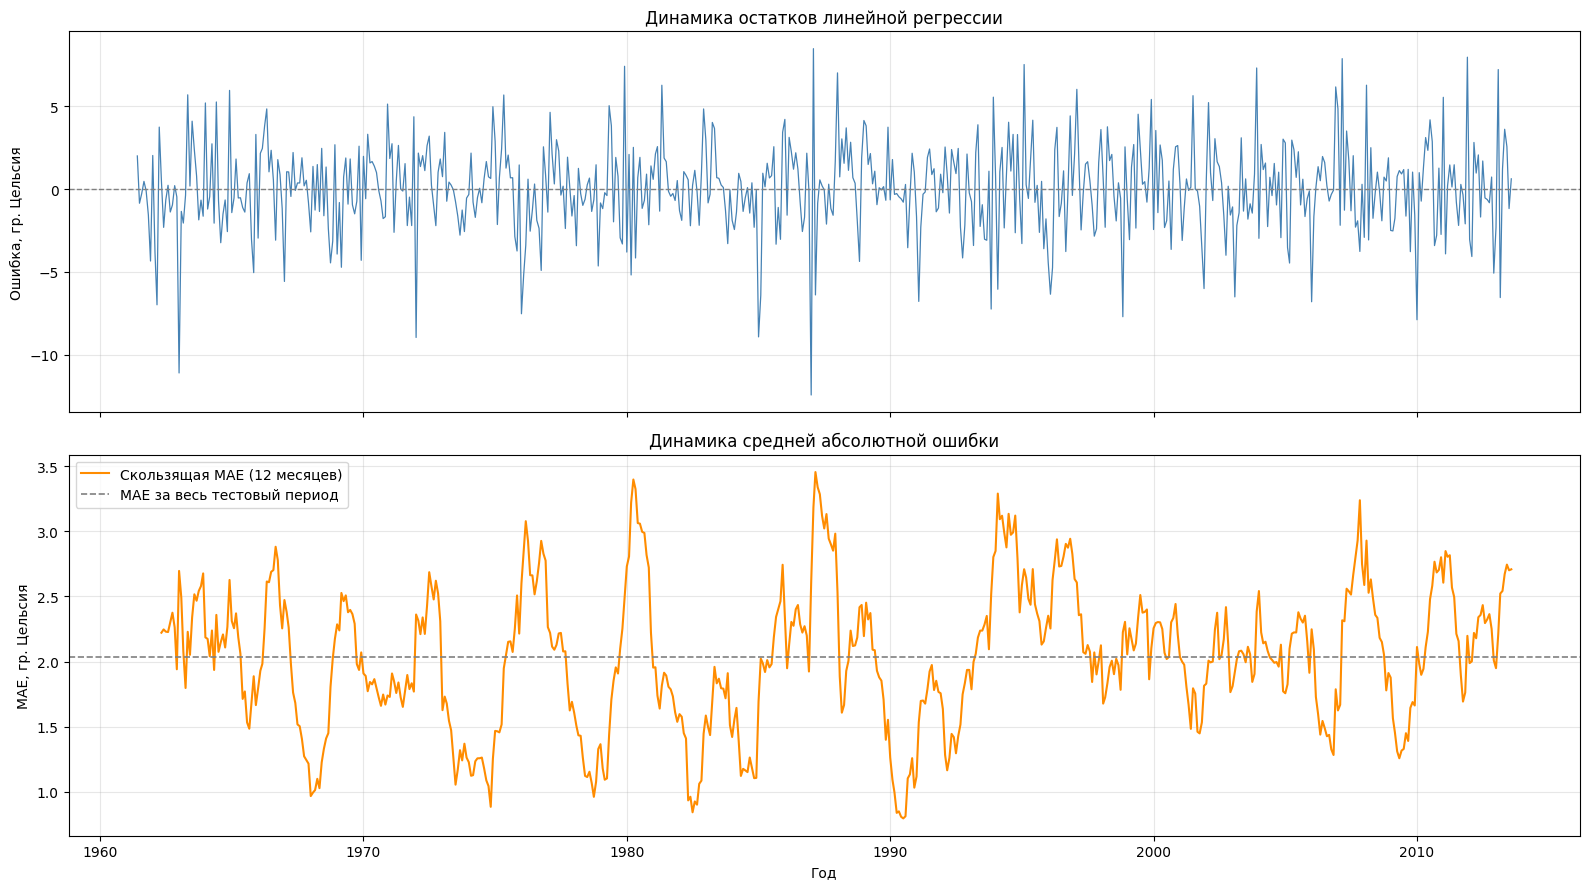

In [210]:
# Расчет скользящей средней абсолютной ошибки
rolling_mae = forecast_results["absolute_error"].rolling(
    window=12,
    min_periods=12,
).mean()

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(16, 9),
    sharex=True,
)

axes[0].plot(
    residuals.index,
    residuals,
    color="steelblue",
    linewidth=0.9,
)

axes[0].axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1,
)

axes[0].set_title("Динамика остатков линейной регрессии")
axes[0].set_ylabel("Ошибка, гр. Цельсия")
axes[0].grid(alpha=0.3)

axes[1].plot(
    rolling_mae.index,
    rolling_mae,
    color="darkorange",
    linewidth=1.5,
    label="Скользящая MAE (12 месяцев)",
)

axes[1].axhline(
    y=linear_regression_metrics["MAE"],
    color="gray",
    linestyle="--",
    linewidth=1.2,
    label="MAE за весь тестовый период",
)

axes[1].set_title("Динамика средней абсолютной ошибки")
axes[1].set_xlabel("Год")
axes[1].set_ylabel("MAE, гр. Цельсия")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### 6.4.3. Распределение остатков

Построим гистограмму распределения остатков линейной регрессии.

Для предварительной оценки систематического смещения прогнозов на графике
дополнительно обозначим нулевое значение и среднее значение остатков.

Близость среднего остатка к нулю свидетельствует о небольшом среднем смещении прогнозов,
однако не гарантирует малой абсолютной ошибки.

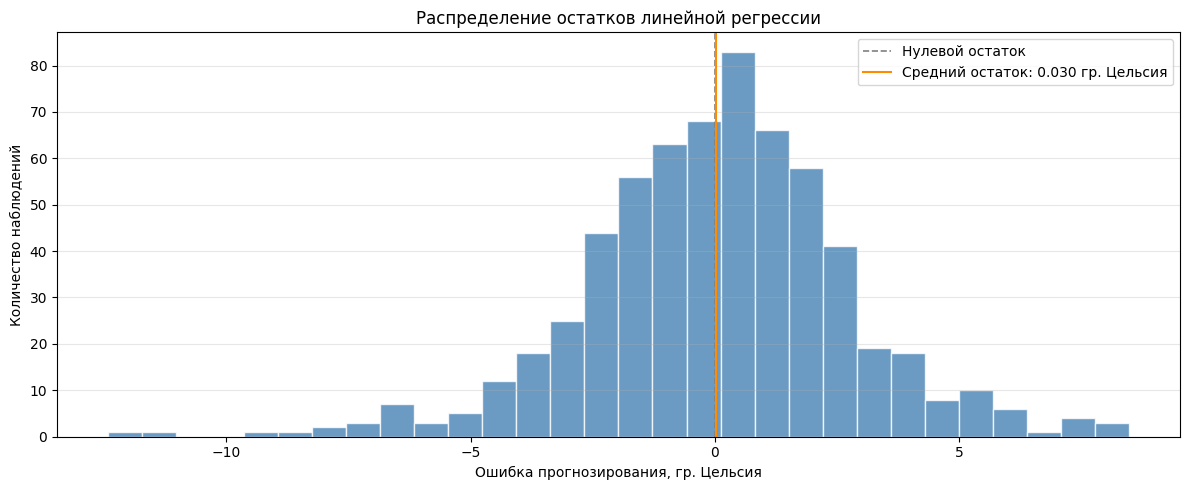

In [211]:
# Визуализация распределения остатков модели
fig, ax = plt.subplots(figsize=(12, 5))

ax.hist(
    residuals,
    bins=30,
    color="steelblue",
    edgecolor="white",
    alpha=0.8,
)

ax.axvline(
    x=0,
    color="gray",
    linestyle="--",
    linewidth=1.2,
    label="Нулевой остаток",
)

ax.axvline(
    x=residuals.mean(),
    color="darkorange",
    linestyle="-",
    linewidth=1.5,
    label=f"Средний остаток: {residuals.mean():.3f} гр. Цельсия",
)

ax.set_title("Распределение остатков линейной регрессии")
ax.set_xlabel("Ошибка прогнозирования, гр. Цельсия")
ax.set_ylabel("Количество наблюдений")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 6.5. Анализ качества прогнозирования по календарным месяцам

По результатам исследовательского анализа временного ряда выявлено,
что изменчивость температур в зимние месяцы выше, чем в летние.

Для проверки предположения о зависимости качества прогнозирования
от сезонности рассчитаем метрики MAE и RMSE отдельно для каждого календарного месяца тестового периода.

Дополнительно определим среднее значение остатка для исследования систематического завышения
или занижения прогнозов в различные месяцы года.

Метрика MAPE в рамках данного анализа не используется вследствие ее повышенной чувствительности
к близким к нулю температурам, особенно характерным для переходных сезонов.

#### 6.5.1. Расчет метрик в разрезе календарных месяцев

In [212]:
# Расчет статистики ошибок по календарным месяцам
monthly_error_stats = (
    forecast_results.groupby(forecast_results.index.month)
    .agg(
        observations_count=("residual", "size"),
        MAE=("absolute_error", "mean"),
        MSE=("squared_error", "mean"),
        mean_error=("residual", "mean"),
    )
)

monthly_error_stats.index.name = "month"

monthly_error_stats["RMSE"] = np.sqrt(
    monthly_error_stats["MSE"]
)

monthly_error_stats = monthly_error_stats[
    [
        "observations_count",
        "MAE",
        "RMSE",
        "mean_error",
    ]
]

monthly_error_stats.round(4)

,observations_count,MAE,RMSE,mean_error
month,,,,
1,52,3.3157,4.3604,-1.2323
2,52,3.1762,3.8117,-0.0442
3,52,2.2204,2.8862,-0.5030
4,52,1.5385,1.8561,0.9884
5,52,2.1615,2.6794,1.3241
6,53,1.5415,1.9064,0.7908
7,53,1.4323,1.8319,0.6746
8,53,1.0433,1.3585,0.1201
9,52,1.5197,1.8665,-0.9277


In [213]:
# Проверка соответствия количества оцененных наблюдений
assert (
    monthly_error_stats["observations_count"].sum()
    == len(y_test)
)

# Определение месяцев с минимальной и максимальной MAE
best_month = monthly_error_stats["MAE"].idxmin()
worst_month = monthly_error_stats["MAE"].idxmax()

print(
    f"Месяц с минимальной MAE: "
    f"{month_labels[best_month - 1]} "
    f"({monthly_error_stats.loc[best_month, 'MAE']:.4f} °C)"
)

print(
    f"Месяц с максимальной MAE: "
    f"{month_labels[worst_month - 1]} "
    f"({monthly_error_stats.loc[worst_month, 'MAE']:.4f} °C)"
)

Месяц с минимальной MAE: Авг (1.0433 °C)
Месяц с максимальной MAE: Янв (3.3157 °C)


#### 6.5.2. Визуализация сезонной зависимости ошибок

Для наглядного сравнения качества прогнозирования в различные месяцы года
построим график значений MAE и RMSE по календарным месяцам.

График позволит определить периоды, характеризующиеся наиболее высокими
и низкими ошибками прогнозирования.

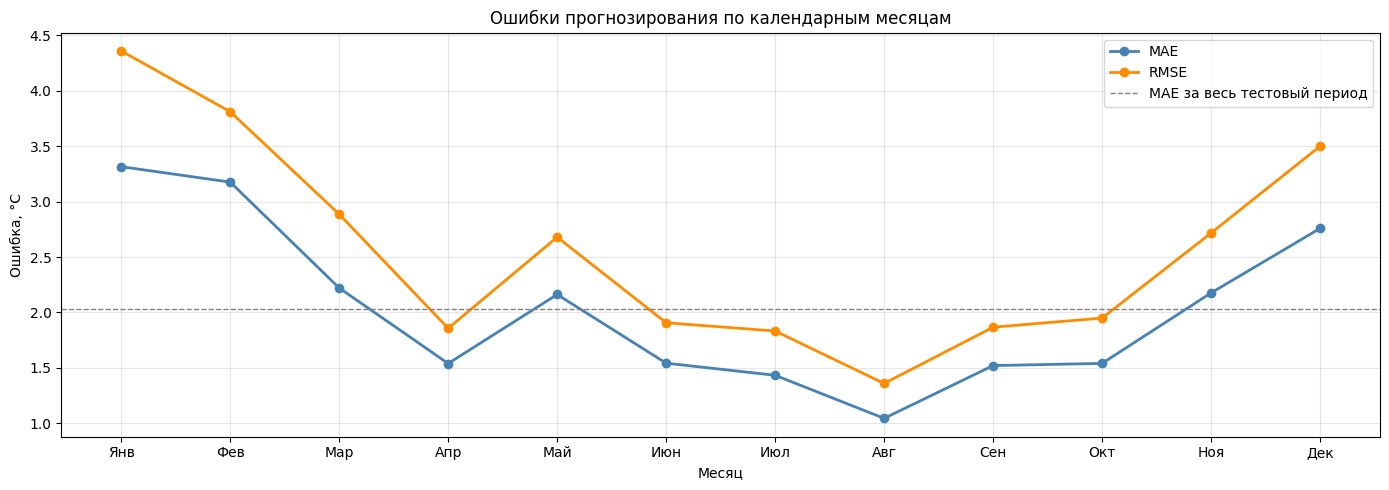

In [214]:
# Визуализация ошибок прогнозирования по месяцам
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    monthly_error_stats.index,
    monthly_error_stats["MAE"],
    color="steelblue",
    marker="o",
    linewidth=2,
    label="MAE",
)

ax.plot(
    monthly_error_stats.index,
    monthly_error_stats["RMSE"],
    color="darkorange",
    marker="o",
    linewidth=2,
    label="RMSE",
)

ax.axhline(
    y=linear_regression_metrics["MAE"],
    color="gray",
    linestyle="--",
    linewidth=1,
    label="MAE за весь тестовый период",
)

ax.set_title("Ошибки прогнозирования по календарным месяцам")
ax.set_xlabel("Месяц")
ax.set_ylabel("Ошибка, °C")
ax.set_xticks(range(1, 13), labels=month_labels)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### 6.5.3. Сравнение качества прогнозирования зимой и летом

Для дополнительной проверки предположения о более высокой сложности прогнозирования зимних температур
сравним агрегированные ошибки прогнозирования для зимнего (декабрь–февраль) и летнего (июнь–август) сезонов.

Метрики рассчитываются непосредственно по всем наблюдениям соответствующего сезона,
а не путем усреднения ранее рассчитанных месячных метрик.

In [215]:
# Выделение зимних и летних наблюдений
winter_mask = forecast_results.index.month.isin(
    WINTER_MONTHS
)

summer_mask = forecast_results.index.month.isin(
    (6, 7, 8)
)

seasonal_error_stats = pd.DataFrame(
    {
        "winter": {
            "observations_count": winter_mask.sum(),
            "MAE": forecast_results.loc[
                winter_mask, "absolute_error"
            ].mean(),
            "RMSE": np.sqrt(
                forecast_results.loc[
                    winter_mask, "squared_error"
                ].mean()
            ),
        },
        "summer": {
            "observations_count": summer_mask.sum(),
            "MAE": forecast_results.loc[
                summer_mask, "absolute_error"
            ].mean(),
            "RMSE": np.sqrt(
                forecast_results.loc[
                    summer_mask, "squared_error"
                ].mean()
            ),
        },
    }
).T

seasonal_error_stats["observations_count"] = (
    seasonal_error_stats["observations_count"].astype(int)
)

seasonal_error_stats.round(4)

,observations_count,MAE,RMSE
winter,156,3.0834,3.9071
summer,159,1.3390,1.7162


In [216]:
# Сравнение ошибок прогнозирования зимой и летом
winter_summer_error_ratio = (
    seasonal_error_stats.loc["winter", ["MAE", "RMSE"]]
    / seasonal_error_stats.loc["summer", ["MAE", "RMSE"]]
)

winter_summer_error_ratio.rename(
    "winter_to_summer_ratio"
).to_frame().round(3)

,winter_to_summer_ratio
MAE,2.303
RMSE,2.277


### 6.6. Выводы по этапу оценки качества прогнозирования

В ходе шестого этапа выполнена количественная оценка качества прогнозирования среднемесячных температур
на отложенной тестовой выборке из `627` наблюдений.

**Результаты сравнения моделей:**

| Модель | MAE, °C | RMSE, °C | MAPE, % |
|---|---:|---:|---:|
| **Linear Regression** | **2.0319** | **2.7079** | **228.2554** |
| Seasonal Naive | 2.2456 | 3.0015 | 253.4956 |

Линейная регрессия показала меньшие значения всех трех метрик по сравнению с базовым сезонным алгоритмом.

Относительное снижение ошибок составило:

- MAE -> `9,51%`
- RMSE -> `9,78%`
- MAPE -> `9,96%`

Полученные результаты подтверждают эффективность использования линейной модели с лаговыми
и календарными признаками относительно простого сезонного правила прогнозирования.

При этом индивидуальный вклад каждого признака отдельно не исследовался.

**Особенности интерпретации MAPE:**

- нулевые фактические температуры в тестовой выборке отсутствуют
- `180` наблюдений содержат отрицательные температуры
- `55` наблюдений (`8,77%`) имеют абсолютное значение температуры менее `1 гр. Цельсия`
- минимальное абсолютное значение фактической температуры составляет `0,004 гр. Цельсия`

Высокие значения MAPE обусловлены, в частности, чувствительностью данной метрики к близким к нулю фактическим значениям.

Дополнительным ограничением является отсутствие естественного абсолютного нуля в шкале Цельсия.

Поэтому основными метриками для интерпретации качества прогнозирования являются MAE и RMSE.

**Анализ остатков:**

- средний остаток составляет `0,0296 гр. Цельсия`,
  что соответствует небольшому среднему занижению прогнозируемых температур
- медианный остаток составляет `0,1485 гр. Цельсия`
- максимальная абсолютная ошибка достигает `12,4251 гр. Цельсия`
- получено `325` заниженных и `302` завышенных прогноза

Близость среднего остатка к нулю свидетельствует о небольшом среднем смещении прогнозов за весь тестовый период,
однако не исключает наличия значительных ошибок отдельных наблюдений или систематических отклонений в отдельных сезонах.

**Сезонная зависимость ошибок:**

- минимальная MAE наблюдается в августе (`1,0433 гр. Цельсия`)
- максимальная MAE наблюдается в январе (`3,3157 гр. Цельсия`)
- MAE зимнего сезона составляет `3,0834 гр. Цельсия`
- MAE летнего сезона составляет `1,3390 гр. Цельсия`
- RMSE зимнего сезона составляет `3,9071 гр. Цельсия`
- RMSE летнего сезона составляет `1,7162 гр. Цельсия`

Ошибки прогнозирования зимой более чем в два раза превышают соответствующие ошибки летом.

Полученные результаты согласуются с выявленной на этапе исследовательского анализа более высокой изменчивостью зимних температур.

Таким образом, линейная регрессия обеспечивает снижение ошибок относительно Seasonal Naive Baseline,
однако качество прогнозирования зависит от календарного сезона, а отдельные температурные аномалии сопровождаются значительными ошибками.

## 7. Итоговые выводы

### 7.1. Основные результаты работы

В рамках домашнего задания реализован полный базовый пайплайн прогнозирования временного ряда среднемесячных температур
на основе открытого датасета `Climate Change: Earth Surface Temperature Data`.

В качестве объекта исследования выбран временной ряд среднемесячных температур Республики Беларусь (`Belarus`).

**Подготовка данных:**

- исследован исходный временной ряд из `3 239` календарных наблюдений
- проанализированы пропущенные значения и продолжительность непрерывных последовательностей пропусков
- выбран непрерывный период с октября 1752 года по август 2013 года
- сформирован регулярный месячный временной ряд из `3 131` наблюдения без пропущенных значений
- сохранено `98,89%` известных температур без искусственного восстановления наблюдений
- выявлена выраженная годовая сезонность с периодом `12` месяцев

**Разбиение временного ряда:**

- реализовано хронологическое Holdout-разбиение в пропорции `80/20`
- сформирована обучающая выборка из `2 504` наблюдений и тестовая выборка из `627` наблюдений
- реализован механизм Rolling Window с обучающим окном `120` месяцев,
  горизонтом прогнозирования `12` месяцев и шагом смещения `12` месяцев
- на обучающей выборке сформировано `198` полных скользящих разбиений

**Генерация признаков:**

- сформированы лаговые признаки `lag_1` и `lag_12`
- добавлены календарные признаки `month` и `is_winter`
- сохранена ранее определенная граница Holdout-разбиения
- подготовлены `2 492` обучающих и `627` тестовых наблюдений с полным набором признаков
- проверено отсутствие использования текущих и будущих значений температуры при формировании входных признаков

**Моделирование и оценка:**

- обучена модель линейной регрессии (`LinearRegression`)
- реализовано прогнозирование по протоколу One-Step-Ahead Forecasting
- получены прогнозы для всех наблюдений тестовой выборки
- рассчитаны метрики MAE, RMSE и MAPE
- выполнено сравнение с базовым сезонным алгоритмом Seasonal Naive
- проведен дополнительный анализ остатков и сезонной зависимости ошибок

### 7.2. Итоговые результаты моделирования

| Модель | MAE, гр. Цельсия | RMSE, гр. Цельсия | MAPE, % |
|---|---:|---:|---:|
| **Linear Regression** | **2.0319** | **2.7079** | **228.2554** |
| Seasonal Naive | 2.2456 | 3.0015 | 253.4956 |

В рамках проведенного эксперимента линейная регрессия показала лучшие результаты по всем рассчитанным метрикам.

Средняя абсолютная ошибка прогнозирования составляет около `2,03 гр. Цельсия`.

По сравнению с Seasonal Naive Baseline достигнуто снижение MAE на `9,51%` и RMSE на `9,78%`.

Высокие значения MAPE свидетельствуют о наличии близких к нулю температур и особенностей шкалы Цельсия.

Дополнительный анализ показал выраженную сезонную зависимость качества прогнозирования,
ошибки зимних прогнозов более чем в два раза превышают ошибки летних прогнозов.

### 7.3. Ограничения исследования

При интерпретации полученных результатов необходимо учитывать следующие ограничения:

- исследование выполнено на данных одной страны
- границы исследуемого периода определены ретроспективно на основании полноты наблюдений
- неопределенность исходных температурных измерений (`AverageTemperatureUncertainty`) не учитывается при моделировании
- используется ограниченный набор лаговых и календарных признаков
- порядковое представление календарного месяца не учитывает его циклическую природу
- долгосрочный климатический тренд отдельно не моделируется
- параметры линейной регрессии остаются неизменными на протяжении всего тестового периода
- прогнозирование выполняется на один месяц вперед при условии доступности фактических предшествующих наблюдений
- многошаговое прогнозирование на горизонте нескольких месяцев не исследовалось
- Rolling Window реализован как механизм формирования временных разбиений, без обучения и оценки модели на каждом скользящем окне
- подбор гиперпараметров и статистическая проверка значимости различий между моделями не выполнялись
- автокорреляция и статистические свойства остатков отдельно не исследовались
- применимость MAPE ограничена особенностями прогнозируемой величины

Полученные результаты характеризуют качество моделей в рамках выбранного датасета,
периода наблюдений и протокола оценки и не должны автоматически переноситься на другие временные ряды или сценарии прогнозирования.

### 7.4. Заключение

В ходе выполнения домашнего задания реализованы основные этапы работы с временными рядами:
исследование и подготовка данных, хронологическое разбиение, формирование скользящих окон,
генерация лаговых и календарных признаков, обучение прогнозной модели
и оценка качества прогнозирования.

Особое внимание уделено сохранению регулярной временной структуры наблюдений,
корректной обработке пропущенных значений и предотвращению утечек данных.

Эксперимент показал, что базовая модель линейной регрессии с ограниченным набором лаговых
и календарных признаков способна учитывать выраженную годовую сезонность температур
и обеспечивать снижение ошибок относительно простого сезонного алгоритма.

Цель работы достигнута, поставленные задачи выполнены.